# Beyond the Unemployment Rate
## India's 2020 labour-market shock: a regional and rural–urban investigation

**May 2019 – June 2020 · 740 observations · 28 named regions · Python / Pandas / statistical investigation**

> **Executive research question** — How did India's observed labour-market conditions change during the early 2020 disruption, how uneven were those changes across geographical groups, and what might a falling unemployment rate leave out?

This is a **reproducible case study**, not a national unemployment release, causal impact estimate or forecasting exercise. The raw material is one Kaggle-hosted CSV. We retain its observations and interrogate its definitions, coverage, geographic variation and internal relationships.

**Reading guide:** every chapter follows **Question → Approach → Evidence → Interpretation → Constraint**. Read the charts and caveats together.

**Dataset attribution:** [Unemployment in India, Kaggle](https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india). The supplied local snapshot, not a newly downloaded version, is analysed here.

### Executive preview
The notebook will quantify the 2020 shock using **a consistent set of geographic groups** and contrast unemployment with labour-force participation and an *implied* employment-to-population percentage. The central analytical tension is whether June's headline improvement also restores the underlying employment share. We will not assume the answer before computing it.

In [1]:
from pathlib import Path
from IPython.display import display, Markdown, Image
import pandas as pd
import numpy as np
from src.analysis import (
    UR, LFPR, EMP, EPR, load_data, checksum, coverage, complete_panel,
    monthly, periods, comparison_table, paired_rural_urban, regional_delta,
    sensitivity, metrics, region_resampling_interval
)
from src.visuals import create_all

ROOT = Path.cwd()
SOURCE = ROOT / 'unemployment_india.csv'
OUT = ROOT / 'assets'
REPORTS = ROOT / 'reports'
REPORTS.mkdir(exist_ok=True)
print('Dataset SHA-256:', checksum(SOURCE))
print('Relative project root:', ROOT.name)

Dataset SHA-256: caa83db2077f8e08ab87e0dd1298c25e698b9c3461b94dad21ab9faad5c72e1b
Relative project root: unemployment-analysis


---
# Chapter 1 · What exactly do we have?

**Question.** Do we have 740 independent people, 740 national monthly estimates, or something else?

**Approach.** Load the seven original fields; validate names, dates, numeric types, ranges, keys and duplicate observations. Define the analytical unit as **region × rural/urban classification × month**. The dataset has no individual-level records.

**Constraint.** These are already **estimated aggregates**. Underlying survey weights, sampling variances and population denominators are not provided, so treating every row as independent survey evidence would overstate precision.

In [2]:
data = load_data(SOURCE)
print(f'Rows: {len(data):,} | Regions: {data.Region.nunique()} | Geographic groups: {data.Unit.nunique()} | Months: {data.Date.nunique()}')
print('Missing required fields:', int(data[["Region","Date",UR,LFPR,EMP,"Area"]].isna().sum().sum()))
print('Duplicate region–area–month keys:', int(data.duplicated(['Region','Area','Date']).sum()))
display(data[['Region','Area','Date',UR,LFPR,EMP,EPR]].head(7))

Rows: 740 | Regions: 28 | Geographic groups: 55 | Months: 14
Missing required fields: 0
Duplicate region–area–month keys: 0


,Region,Area,Date,Estimated Unemployment Rate (%),Estimated Labour Participation Rate (%),Estimated Employed,Implied employed share (%)
0,Andhra Pradesh,Rural,2019-05-31,3.65,43.24,11999139,41.661740
1,Andhra Pradesh,Rural,2019-06-30,3.05,42.05,11755881,40.767475
2,Andhra Pradesh,Rural,2019-07-31,3.75,43.50,12086707,41.868750
3,Andhra Pradesh,Rural,2019-08-31,3.32,43.97,12285693,42.510196
4,Andhra Pradesh,Rural,2019-09-30,5.17,44.68,12256762,42.370044
5,Andhra Pradesh,Rural,2019-10-31,3.52,43.01,12017412,41.496048
6,Andhra Pradesh,Rural,2019-11-30,4.12,41.00,11397681,39.310800


## The indicators and their denominators

- **Unemployment rate (UR)**: share of the labour force classified as unemployed (as provided in the CSV).
- **Labour-force participation rate (LFPR)**: reported labour-force share of the corresponding reference population.
- **Estimated employed count**: an *absolute* count. Comparing counts across regions of different sizes is not equivalent to comparing employment rates.
- **Implied employed share (EPR proxy)**: derived for each row as

\[
\mathrm{EPR}_{proxy} = \mathrm{LFPR}\left(1-\frac{\mathrm{UR}}{100}\right).
\]

**Important:** this derived ratio is meaningful only if UR and LFPR use compatible working-age/reference-population definitions and estimation universes. We therefore call it an **implied employed share** throughout, not an official employment-to-population ratio. Compute it *at row level before averaging*, rather than multiplying independently averaged UR and LFPR.

In [3]:
print('Observed variable ranges:')
display(pd.DataFrame({'Minimum':data[[UR,LFPR,EMP,EPR]].min(),'Maximum':data[[UR,LFPR,EMP,EPR]].max()}))
assert data[UR].between(0,100).all() and data[LFPR].between(0,100).all()
assert np.allclose(data[EPR],data[LFPR]*(1-data[UR]/100))

Observed variable ranges:


,Minimum,Maximum
Estimated Unemployment Rate (%),0.0000,7.674000e+01
Estimated Labour Participation Rate (%),13.3300,7.257000e+01
Estimated Employed,49420.0000,4.577751e+07
Implied employed share (%),7.8125,6.898430e+01


---
# Chapter 2 · Missing time periods can be invisible

**Question.** Does every geographic group contribute observations every month?

**Approach.** Construct the full matrix of **observed** region–area groups by months. No missing values appear inside the CSV, but some expected combinations of observed units and months are absent. This is different from blank cells.

Of the 28 named regions, 27 have both area categories somewhere in the file; the other appears only as an urban grouping. A theoretical 28 × 2 × 14 grid does not by itself identify true missing records, because the data source may not define all combinations. We therefore report gaps **within the 55 observed groups**.

In [4]:
present = coverage(data)
complete = complete_panel(data)
s = metrics(data,complete)
display(Markdown(f"""**Audit outcome.** {s['area_units_raw']} observed geographic groups × {s['months']} months = {s['area_units_raw']*s['months']} possible observed-group/month cells. **{s['observed_panel_gaps']} combinations are absent**. Only **{s['complete_units']} groups** (across {s['complete_regions']} regions) have all 14 months. The constant comparison sample contains **{s['balanced_rows']} rows**."""))
display(present.sum(axis=1).value_counts().sort_index().rename('Geographic groups by observed-month count').to_frame().T)

**Audit outcome.** 55 observed geographic groups × 14 months = 770 possible observed-group/month cells. **30 combinations are absent**. Only **44 groups** (across 24 regions) have all 14 months. The constant comparison sample contains **616 rows**.

,5,10,11,12,13,14
Geographic groups by observed-month count,1,1,1,6,2,44


### Exhibit 1 · The coverage matrix
Missing cells are shown explicitly; they are not filled with zeros or fabricated. The balanced panel is a **sensitivity design**, not a claim that excluded regions are irrelevant. Complete-case filtering creates a narrower geographic sample with its own selection limitations.

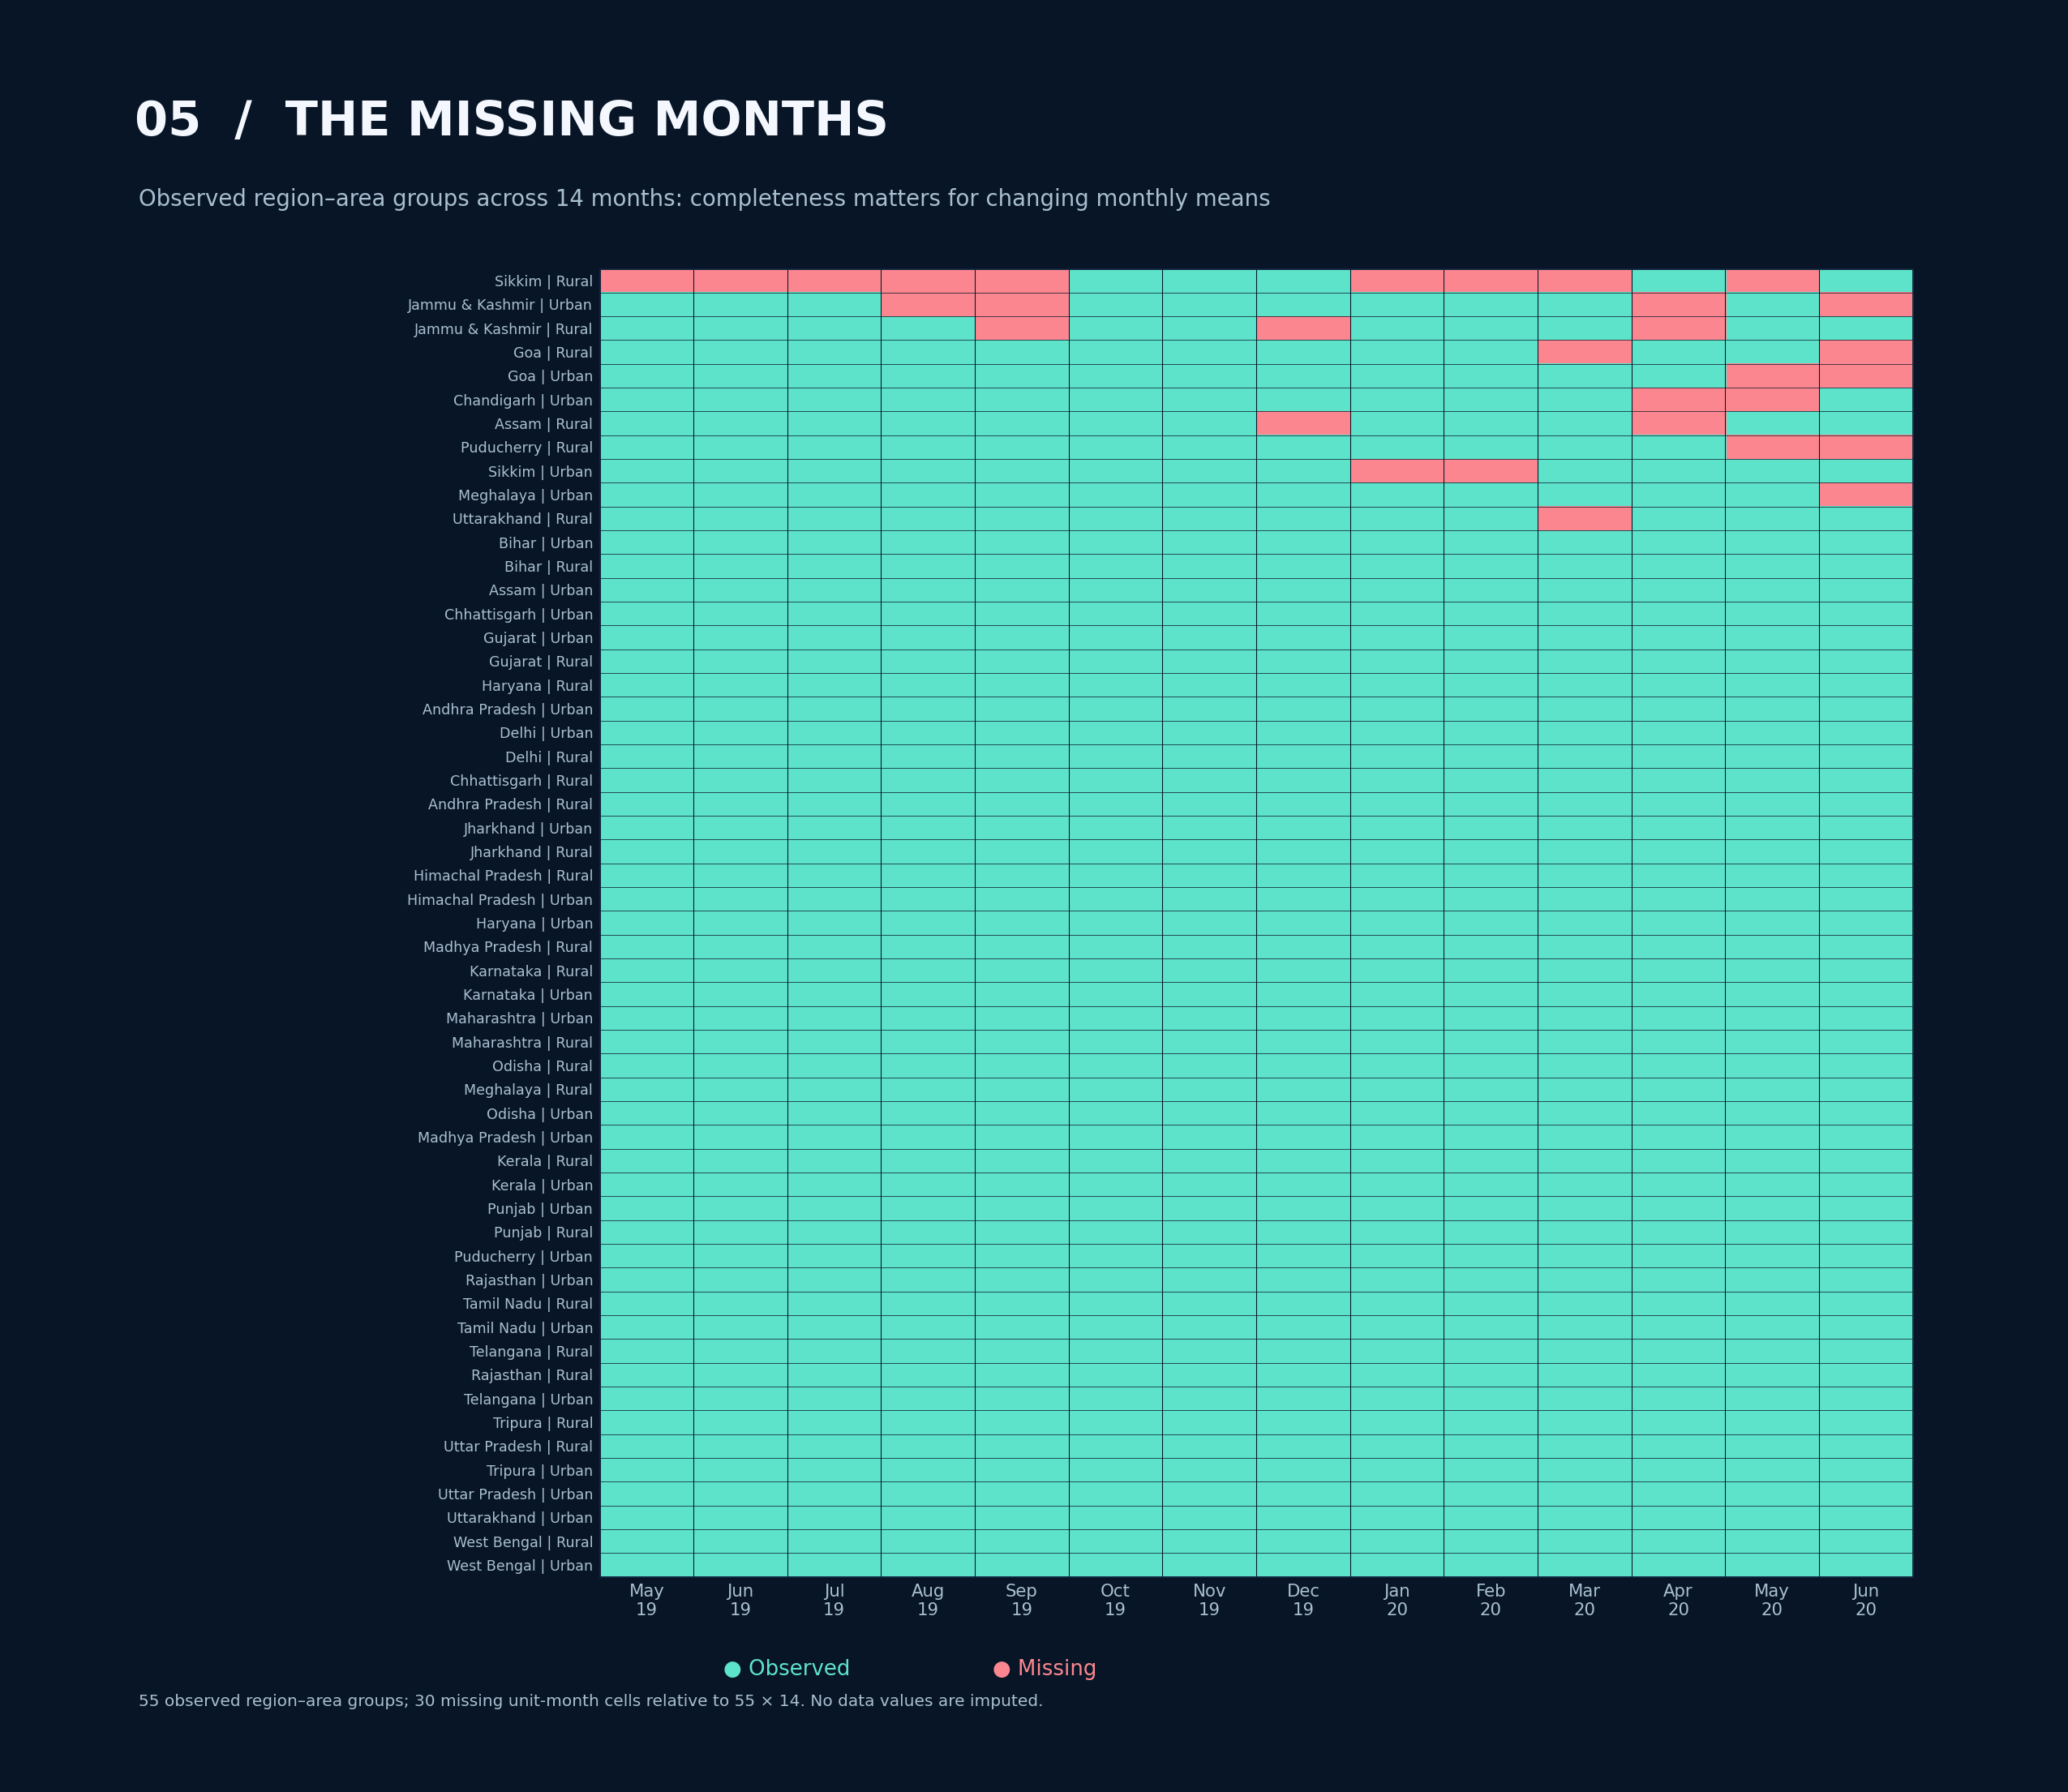

In [5]:
figures = create_all(data,complete,OUT)
display(Image(filename=str(OUT/'05_coverage_matrix.png'),width=1150))

---
# Chapter 3 · Define the comparison before interpreting it

**Question.** Against what should the 2020 shock be compared?

We partition 14 monthly observations into four descriptive windows:

| Window | Dates | Interpretation |
|---|---|---|
| Pre-shock baseline | May 2019 – February 2020 (10 months) | Each geographic group's average earlier conditions |
| Transition | March 2020 | The month containing the initial nationwide restrictions |
| Shock window | April – May 2020 (2 months) | Acute labour-market disruption in this dataset |
| Initial June reading | June 2020 (1 month) | Short-horizon improvement check, **not** long-run recovery |

For the primary analysis, every one of the **44 complete geographic groups** contributes equally. We first average within each group over the specified window, then average across groups. Comparisons are expressed as **percentage points**, not percent changes, and are descriptive rather than causal.

In [6]:
paired = comparison_table(complete)
period_means = pd.DataFrame({
    'Baseline': [paired.ur_baseline.mean(),paired.lfpr_baseline.mean(),paired.employed_share_baseline.mean()],
    'Apr–May': [paired.ur_shock.mean(),paired.lfpr_shock.mean(),paired.employed_share_shock.mean()],
    'June': [paired.ur_june.mean(),paired.lfpr_june.mean(),paired.employed_share_june.mean()],
},index=['Unemployment rate','Participation rate','Implied employed share'])
display(period_means.style.format('{:.2f}%'))

,Baseline,Apr–May,June
Unemployment rate,9.69%,25.71%,12.50%
Participation rate,44.06%,36.23%,41.23%
Implied employed share,39.62%,26.78%,36.05%


---
# Chapter 4 · How large was the unemployment shock?

**Question.** Do consistent geographic groups show an exceptional April–May deterioration?

**Approach.** Compare the complete-panel monthly mean with the traditional all-available-row mean. The latter is important for relating findings back to the original notebook; the former keeps the geographic composition fixed.

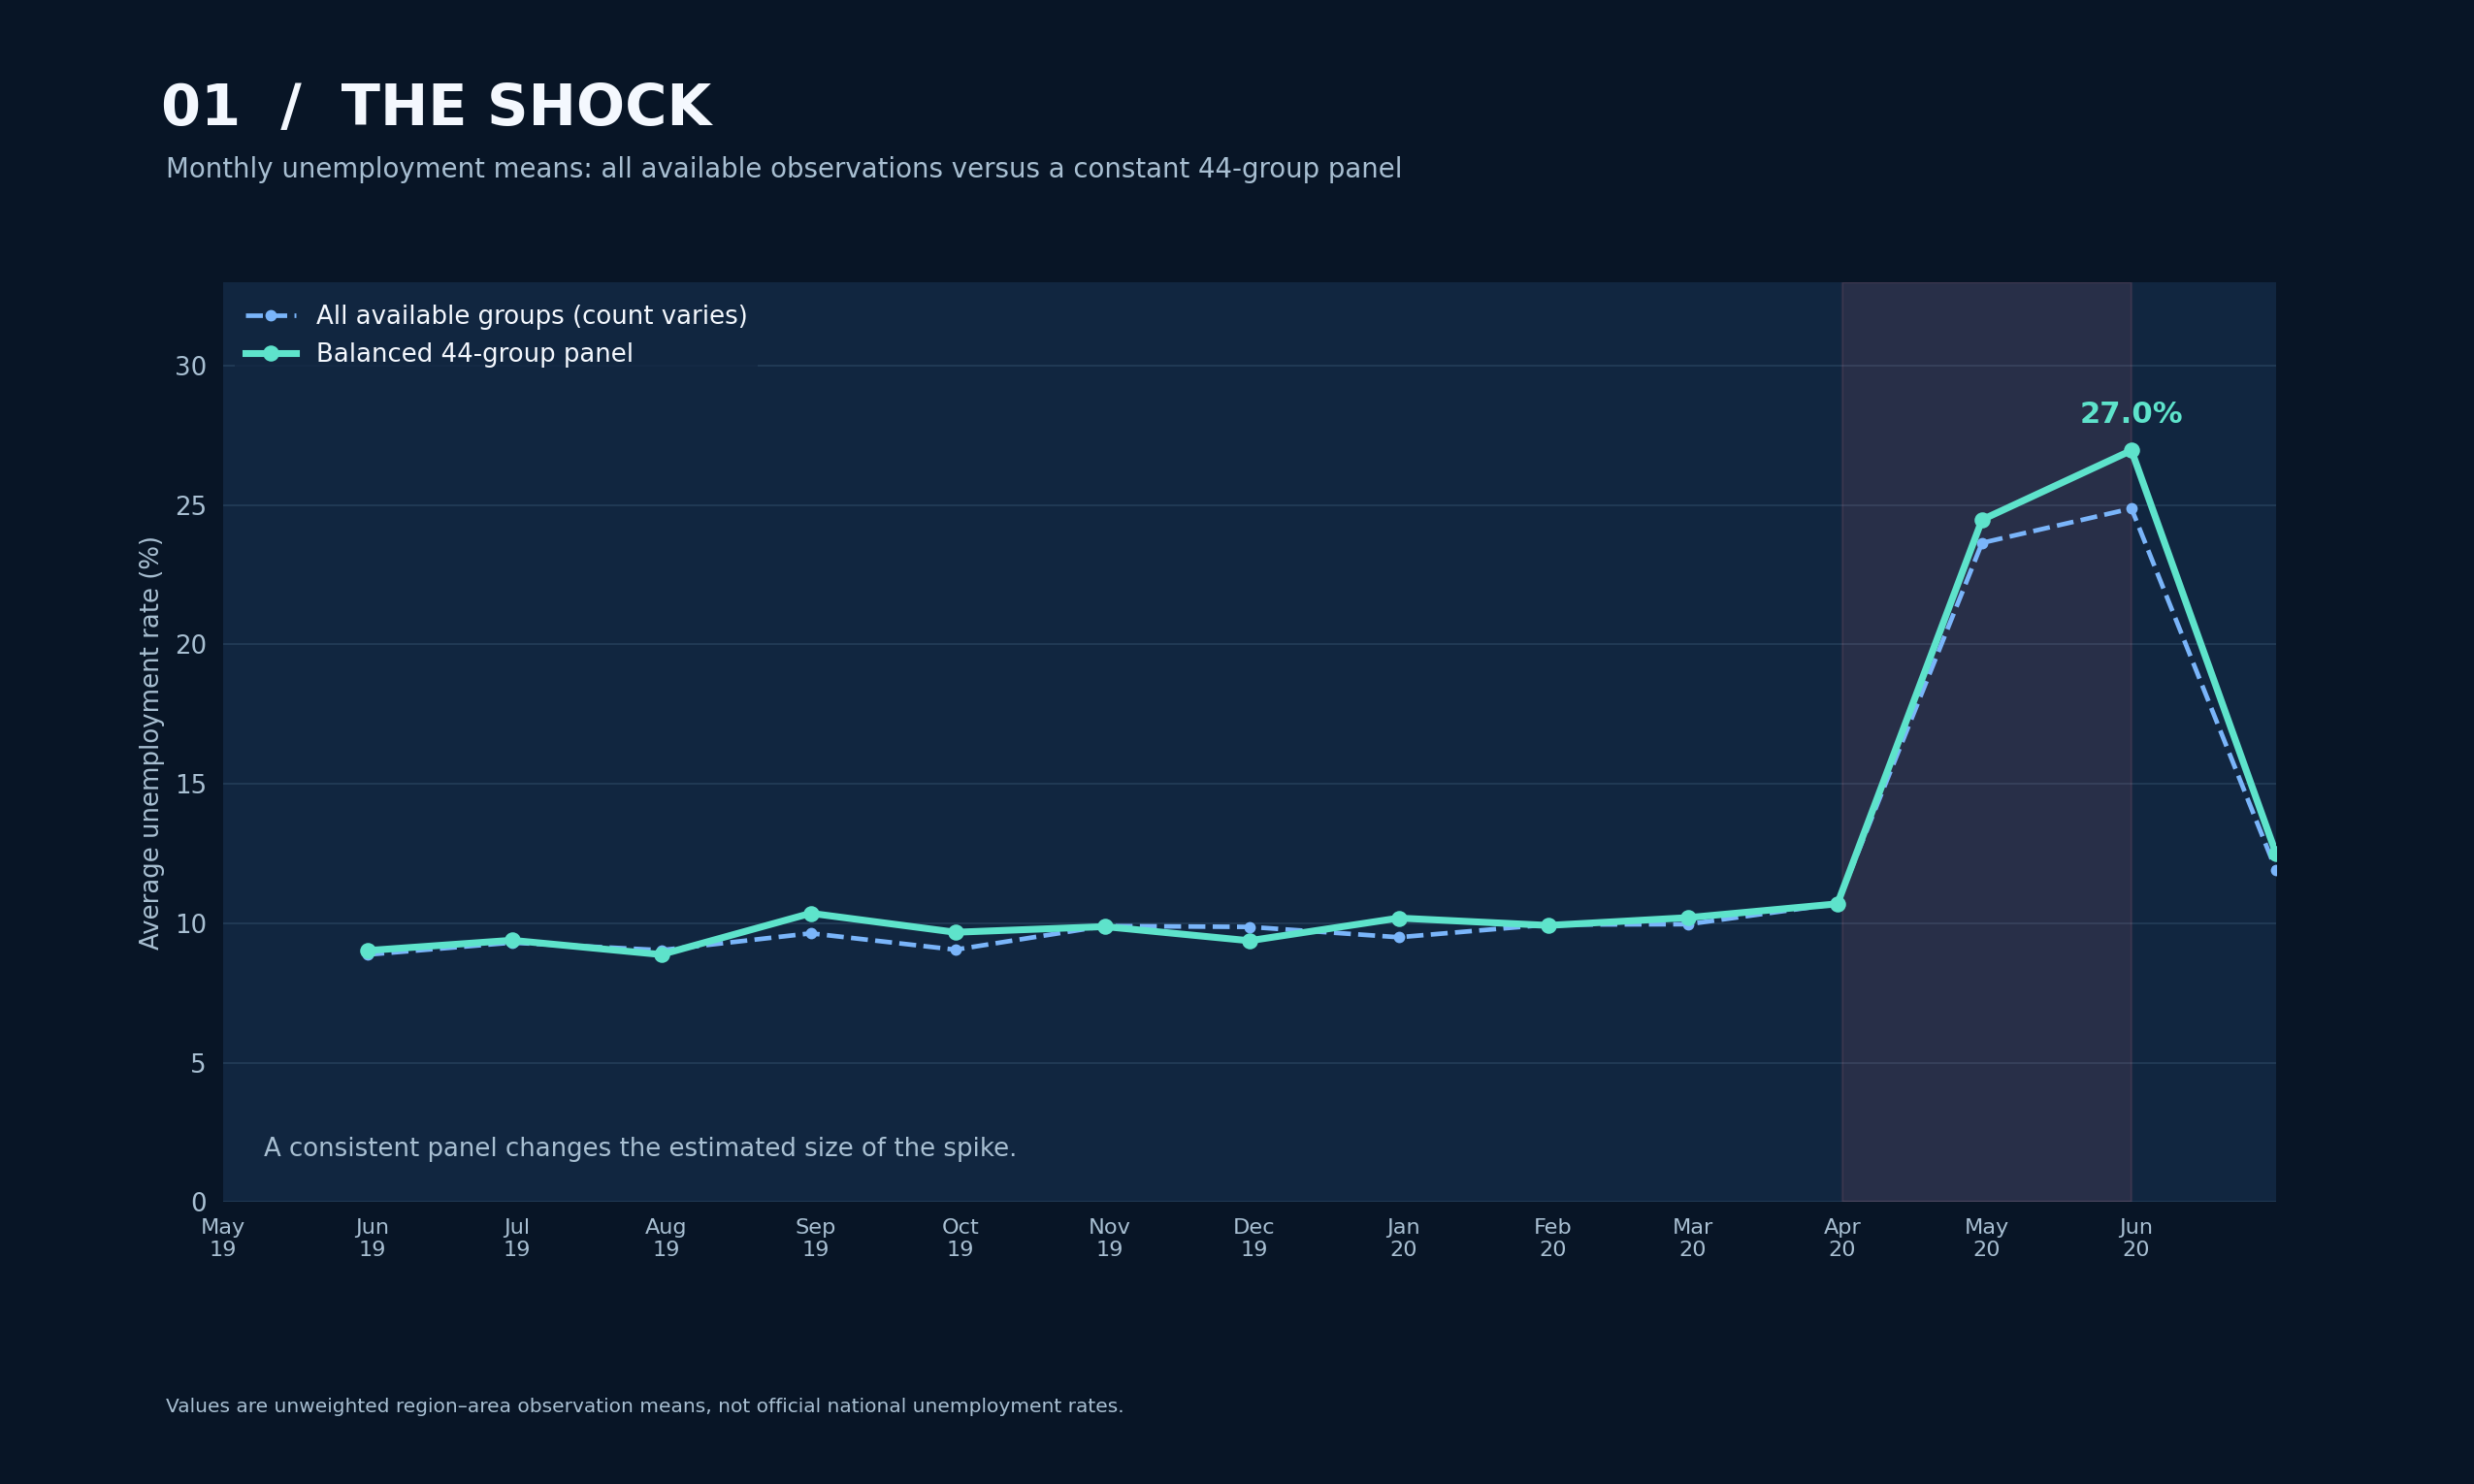

,All available groups (%),Balanced 44 groups (%),Available group count
Date,,,
2020-02-29 00:00:00,9.96,10.20,53
2020-03-31 00:00:00,10.70,10.70,52
2020-04-30 00:00:00,23.64,24.47,51
2020-05-31 00:00:00,24.88,26.96,51
2020-06-30 00:00:00,11.90,12.50,50


In [7]:
display(Image(filename=str(OUT/'01_unemployment_trend.png'),width=1120))
month_all = monthly(data)
month_balanced = monthly(complete)
display(pd.DataFrame({
 'All available groups (%)':month_all.unemployment,
 'Balanced 44 groups (%)':month_balanced.unemployment,
 'Available group count':month_all.units,
}).tail(5).style.format({'All available groups (%)':'{:.2f}','Balanced 44 groups (%)':'{:.2f}'}))

In [8]:
display(Markdown(f"""**Observed result.** In the 44-group panel, the baseline mean was **{s['baseline_ur']:.2f}%** and the April–May mean was **{s['shock_ur']:.2f}%**, an increase of **{s['ur_shock_pp']:.2f} percentage points**. **{s['units_ur_up_shock']} of {s['complete_units']} groups** recorded an increase. The older all-available-data series reported **{s['mar_all_ur']:.2f}%** in March, **{s['apr_all_ur']:.2f}%** in April and **{s['may_all_ur']:.2f}%** in May.

**Interpretation.** The broad shock is evident, but its reported magnitude depends on the sample definition. Neither series is an official national rate, and this is not an estimate of what would have happened without the pandemic."""))

**Observed result.** In the 44-group panel, the baseline mean was **9.69%** and the April–May mean was **25.71%**, an increase of **16.03 percentage points**. **40 of 44 groups** recorded an increase. The older all-available-data series reported **10.70%** in March, **23.64%** in April and **24.88%** in May.

**Interpretation.** The broad shock is evident, but its reported magnitude depends on the sample definition. Neither series is an official national rate, and this is not an estimate of what would have happened without the pandemic.

---
# Chapter 5 · Geographic heterogeneity: changes, not just levels

**Question.** Were geographic groups affected equally?

**Approach.** Subtract each geographic group's ten-month baseline unemployment mean from its April–May mean. Aggregate to a regional mean across its 1–2 complete area groups. A geographic region with unusually high unemployment even before 2020 is not necessarily the region with the largest change.

**Constraint.** Rankings describe the included groups; they are not population-weighted state rankings and can be sensitive to outliers, missing histories, small cells and regional representation.

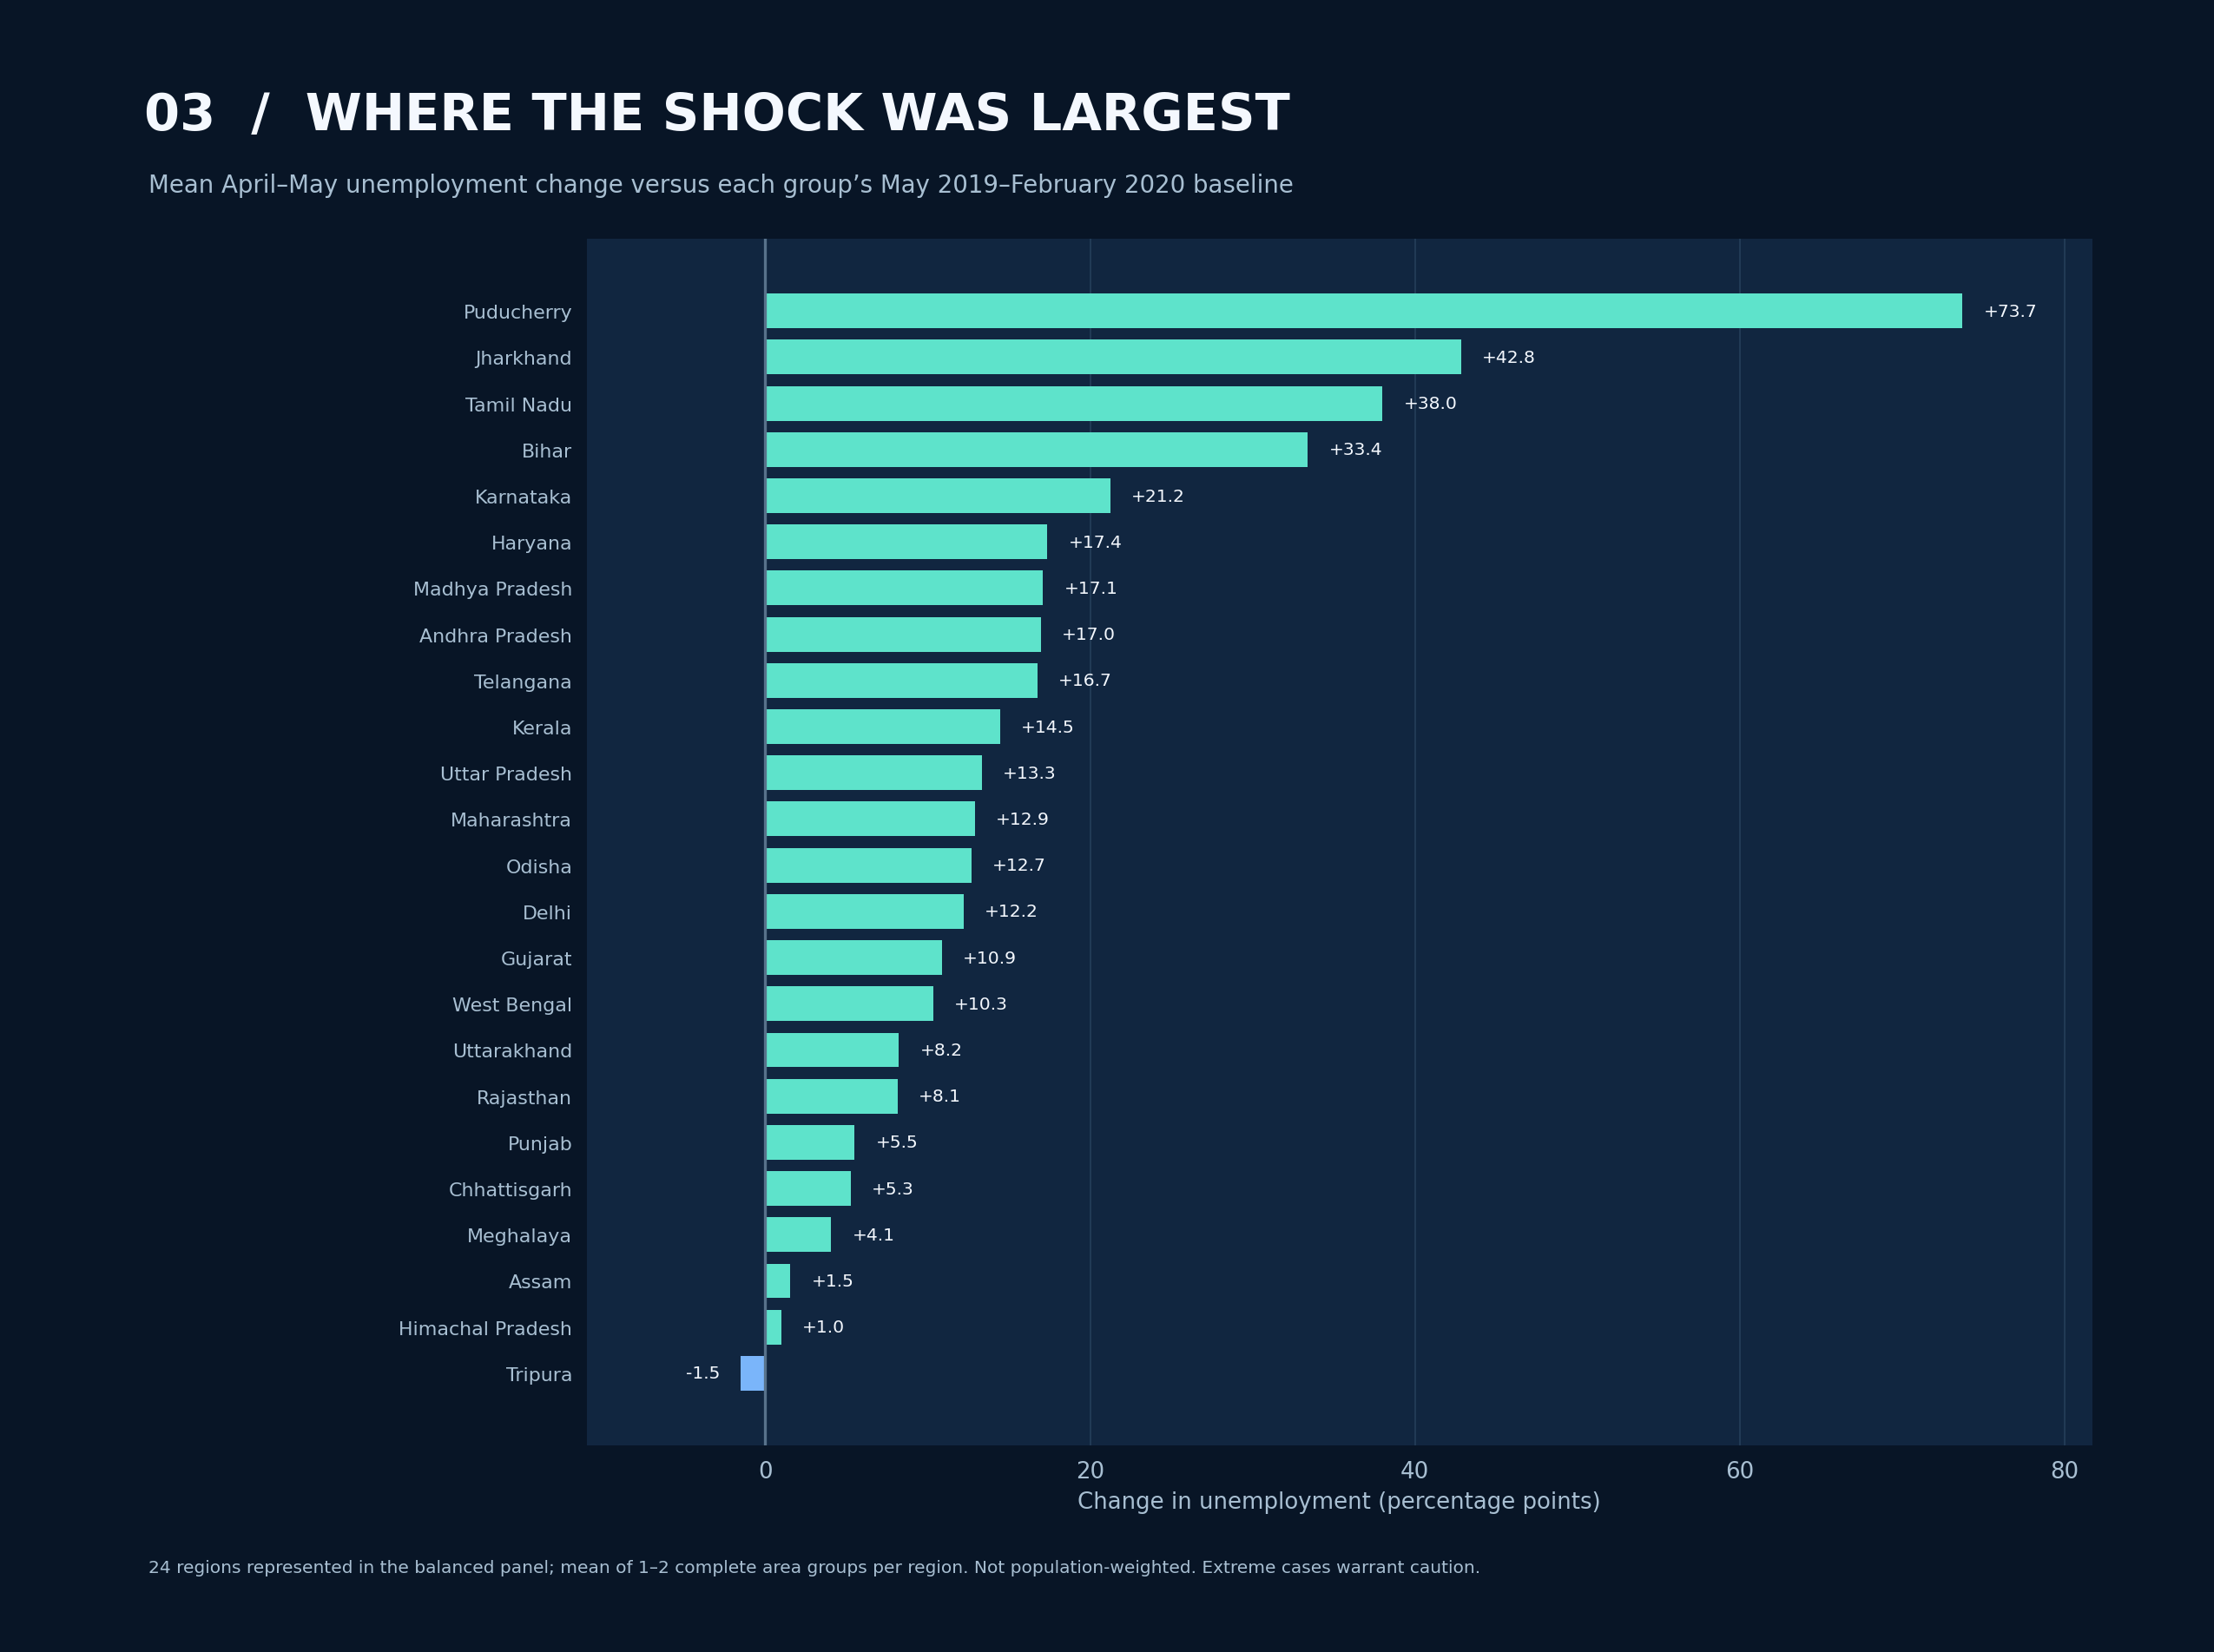

,unit_count,shock_unemployment_pp,june_unemployment_pp,shock_employed_share_pp
Region,,,,
Puducherry,1,+73.72,+2.40,-28.39
Jharkhand,2,+42.84,+6.18,-19.96
Tamil Nadu,2,+38.02,+10.66,-26.64
Bihar,2,+33.41,+2.64,-13.51
Karnataka,2,+21.24,+5.29,-6.58
Haryana,2,+17.36,+9.55,-8.42
Madhya Pradesh,2,+17.11,+4.85,-9.85
Andhra Pradesh,2,+16.95,-1.68,-11.63


In [9]:
display(Image(filename=str(OUT/'03_geographic_changes.png'),width=1100))
reg = regional_delta(paired)
display(reg.sort_values('shock_unemployment_pp',ascending=False).head(8).style.format({'shock_unemployment_pp':'{:+.2f}','june_unemployment_pp':'{:+.2f}','shock_employed_share_pp':'{:+.2f}'}))

### Influence check · One extreme should not decide our story
A region–area group with an unusually large April–May increase is analytically important, but we should not use its value to characterise every region. We retain the observation (no evidence it is a data error), then compare the all-group mean with a sensitivity calculation omitting just that one influential group. This is a **diagnostic**, not a preferred revised estimate. The median across all 44 groups provides another useful reference.

In [10]:
display(Markdown(f"""The largest complete-group increase was **{s['largest_shock_unit']}** (**+{s['largest_shock_unit_change_pp']:.2f} percentage points**). The complete-panel mean shock was **+{s['ur_shock_pp']:.2f} pp**, versus **+{s['mean_ur_shock_without_largest_pp']:.2f} pp** with this one group excluded; the full-sample median was **+{s['shock_ur_median_delta_pp']:.2f} pp**. The qualitative conclusion of a broad shock does not depend on the single most extreme group, though the mean magnitude is sensitive to it."""))

The largest complete-group increase was **Puducherry | Urban** (**+73.72 percentage points**). The complete-panel mean shock was **+16.03 pp**, versus **+14.69 pp** with this one group excluded; the full-sample median was **+13.31 pp**. The qualitative conclusion of a broad shock does not depend on the single most extreme group, though the mean magnitude is sensitive to it.

---
# Chapter 6 · Rural versus urban: compare within the same region

**Question.** Was the unemployment-rate change consistently larger in urban than in rural areas?

**Approach.** Restrict the comparison to regions containing *both* rural and urban groups with complete 14-month histories. Compare the April–May minus baseline change for each area, within the same region. We therefore compare **rates and changes**, unlike the original notebook's independent t-test on employed **counts**.

This is a matched descriptive comparison of 20 regions. With no original survey design information, we do not assign survey population p-values to these points.

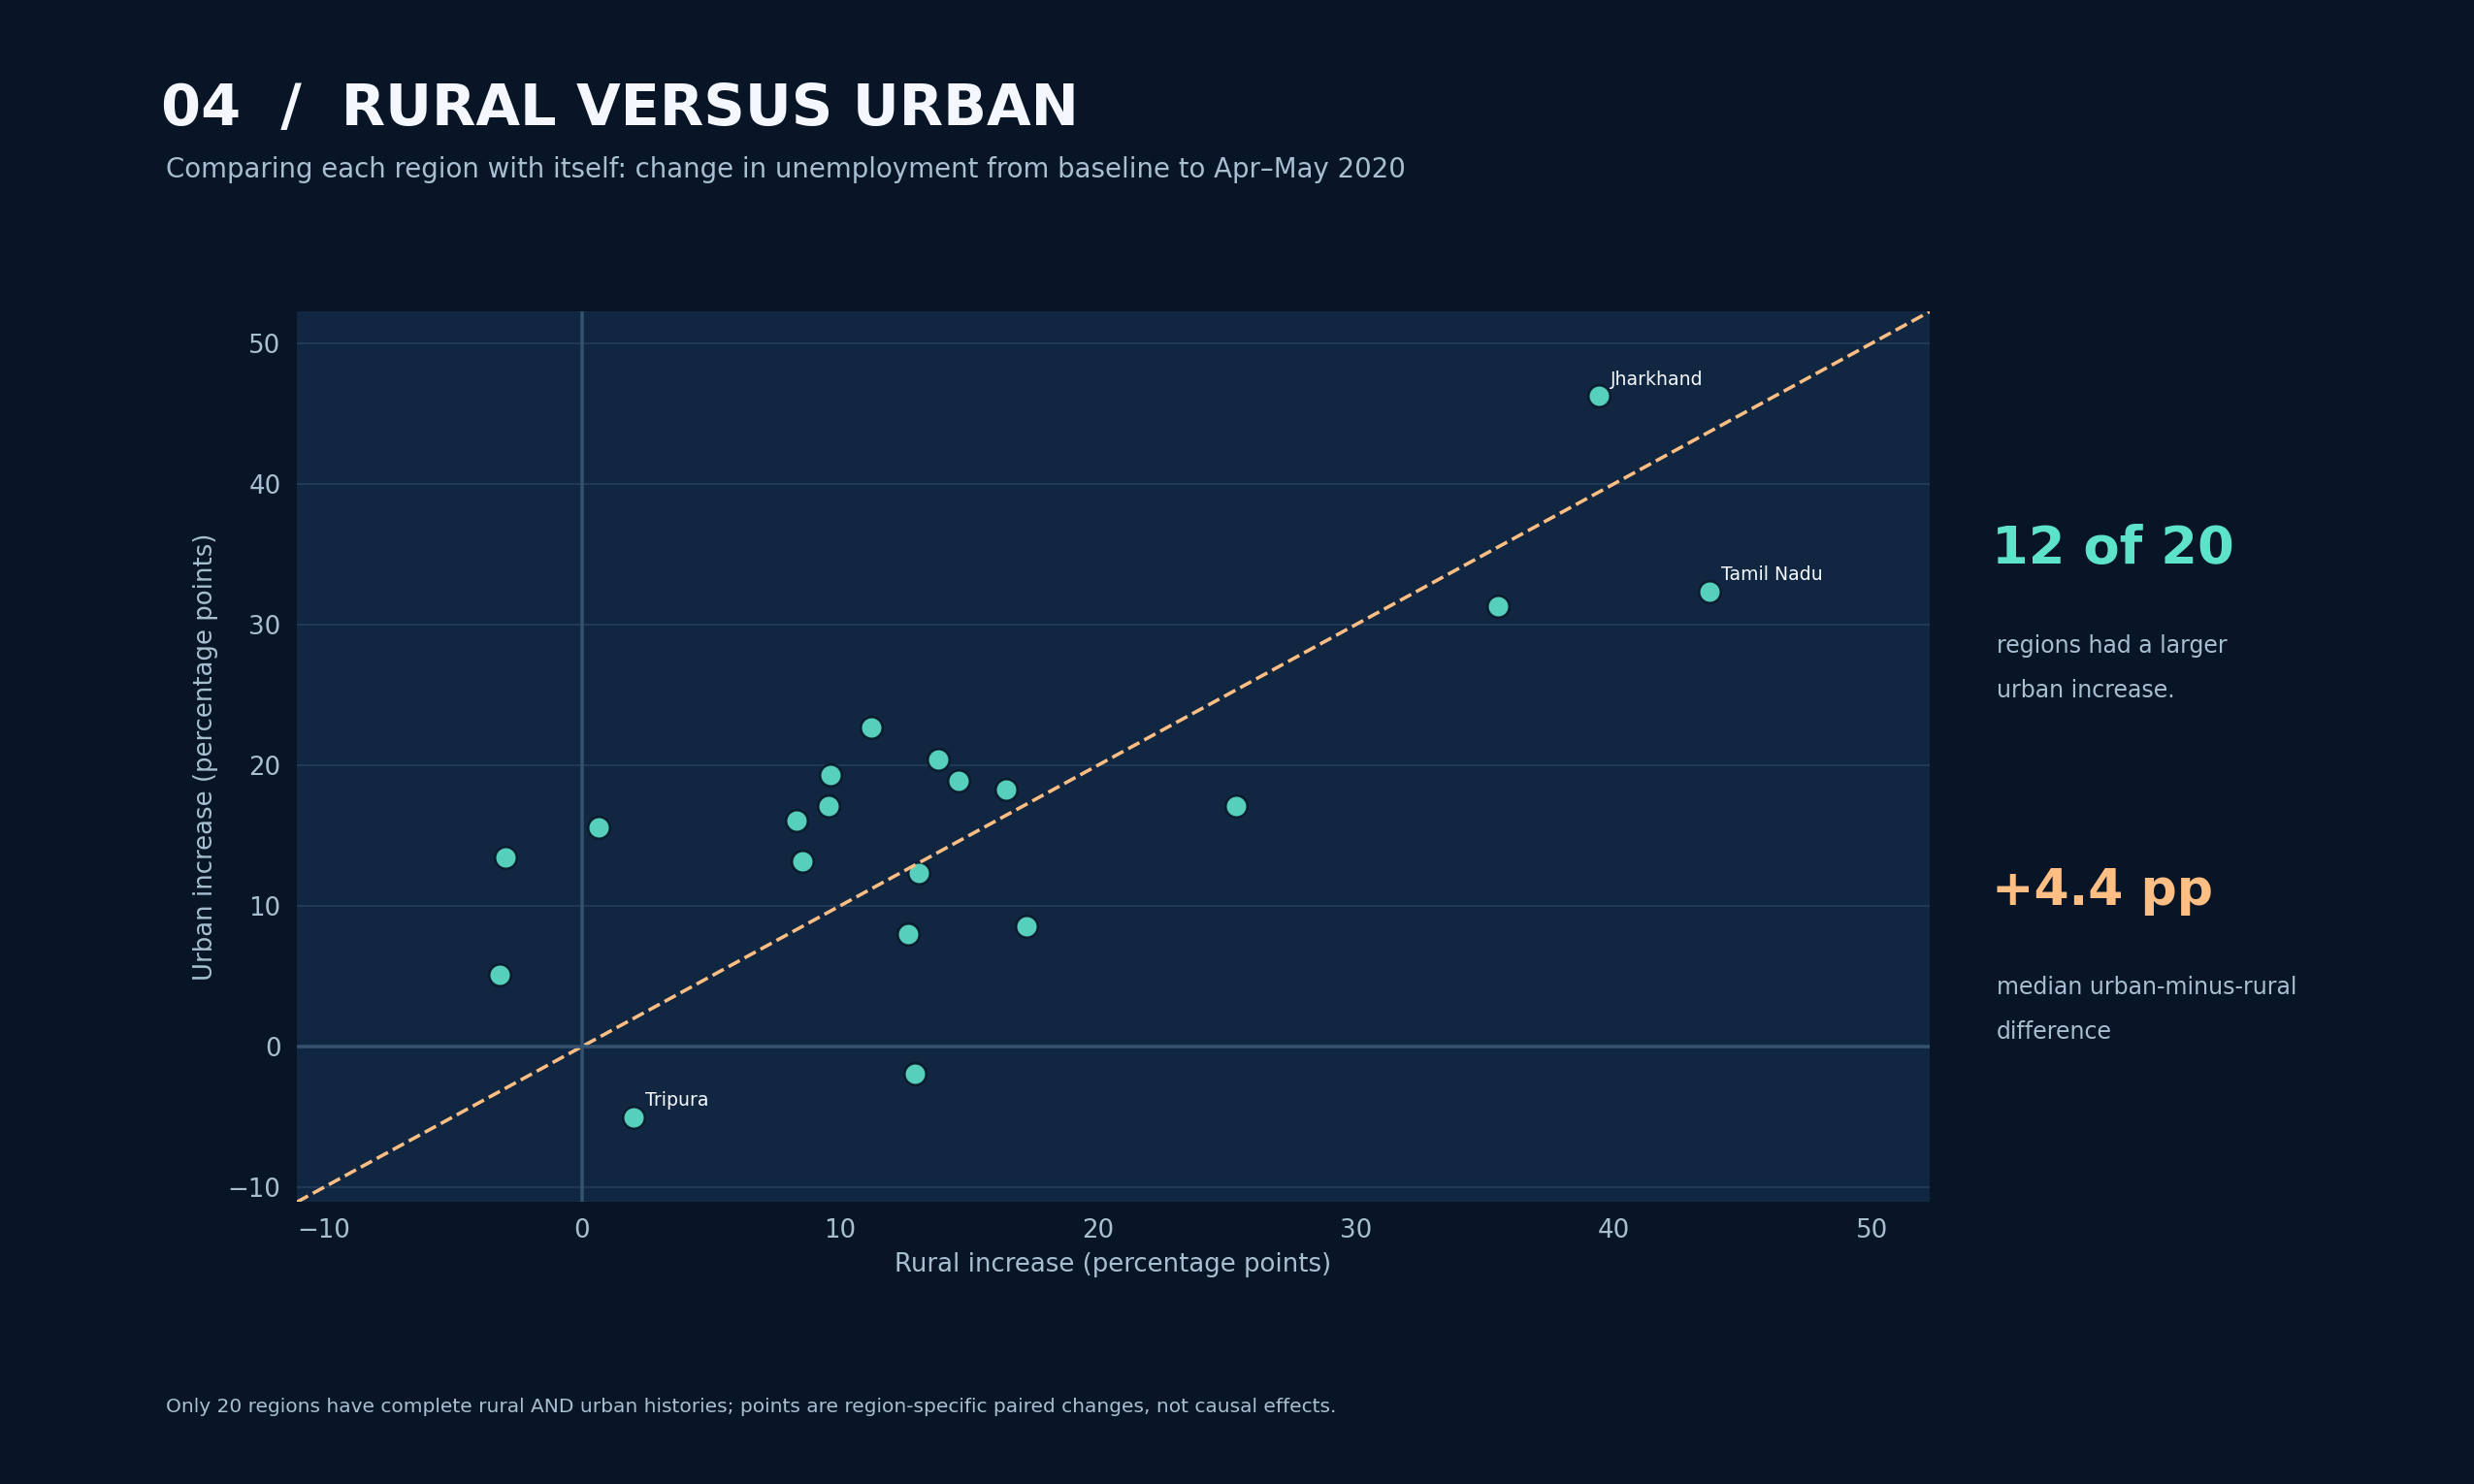

In **20 region pairs**, the urban unemployment increase exceeded the rural increase in **12**. The **median urban-minus-rural change was +4.44 percentage points**. The evidence therefore does **not** support a universal statement that one area category was always hit harder. The result applies to fully observed region pairs, not necessarily to all Indian rural and urban populations.

In [11]:
display(Image(filename=str(OUT/'04_rural_urban_comparison.png'),width=1100))
ru = paired_rural_urban(paired)
display(Markdown(f"""In **{s['paired_rural_urban_regions']} region pairs**, the urban unemployment increase exceeded the rural increase in **{s['matched_area_urban_greater']}**. The **median urban-minus-rural change was {s['matched_area_median_difference_pp']:+.2f} percentage points**. The evidence therefore does **not** support a universal statement that one area category was always hit harder. The result applies to fully observed region pairs, not necessarily to all Indian rural and urban populations."""))

---
# Chapter 7 · Beyond the headline: participation and employed share

**Question.** Does the falling unemployment rate in June mean the same fraction of the reference population was employed again?

**Approach.** Plot three indicators over the same balanced 44-group panel: unemployment, reported participation and an implied employed share calculated from each original record. Each indicator's baseline and June values can move in different directions.

**Measurement caution.** The implied employed share is a derived identity under consistent UR/LFPR definitions; it does not reveal people's reasons for labour-force exit and does not replace a surveyed employment-to-population ratio.

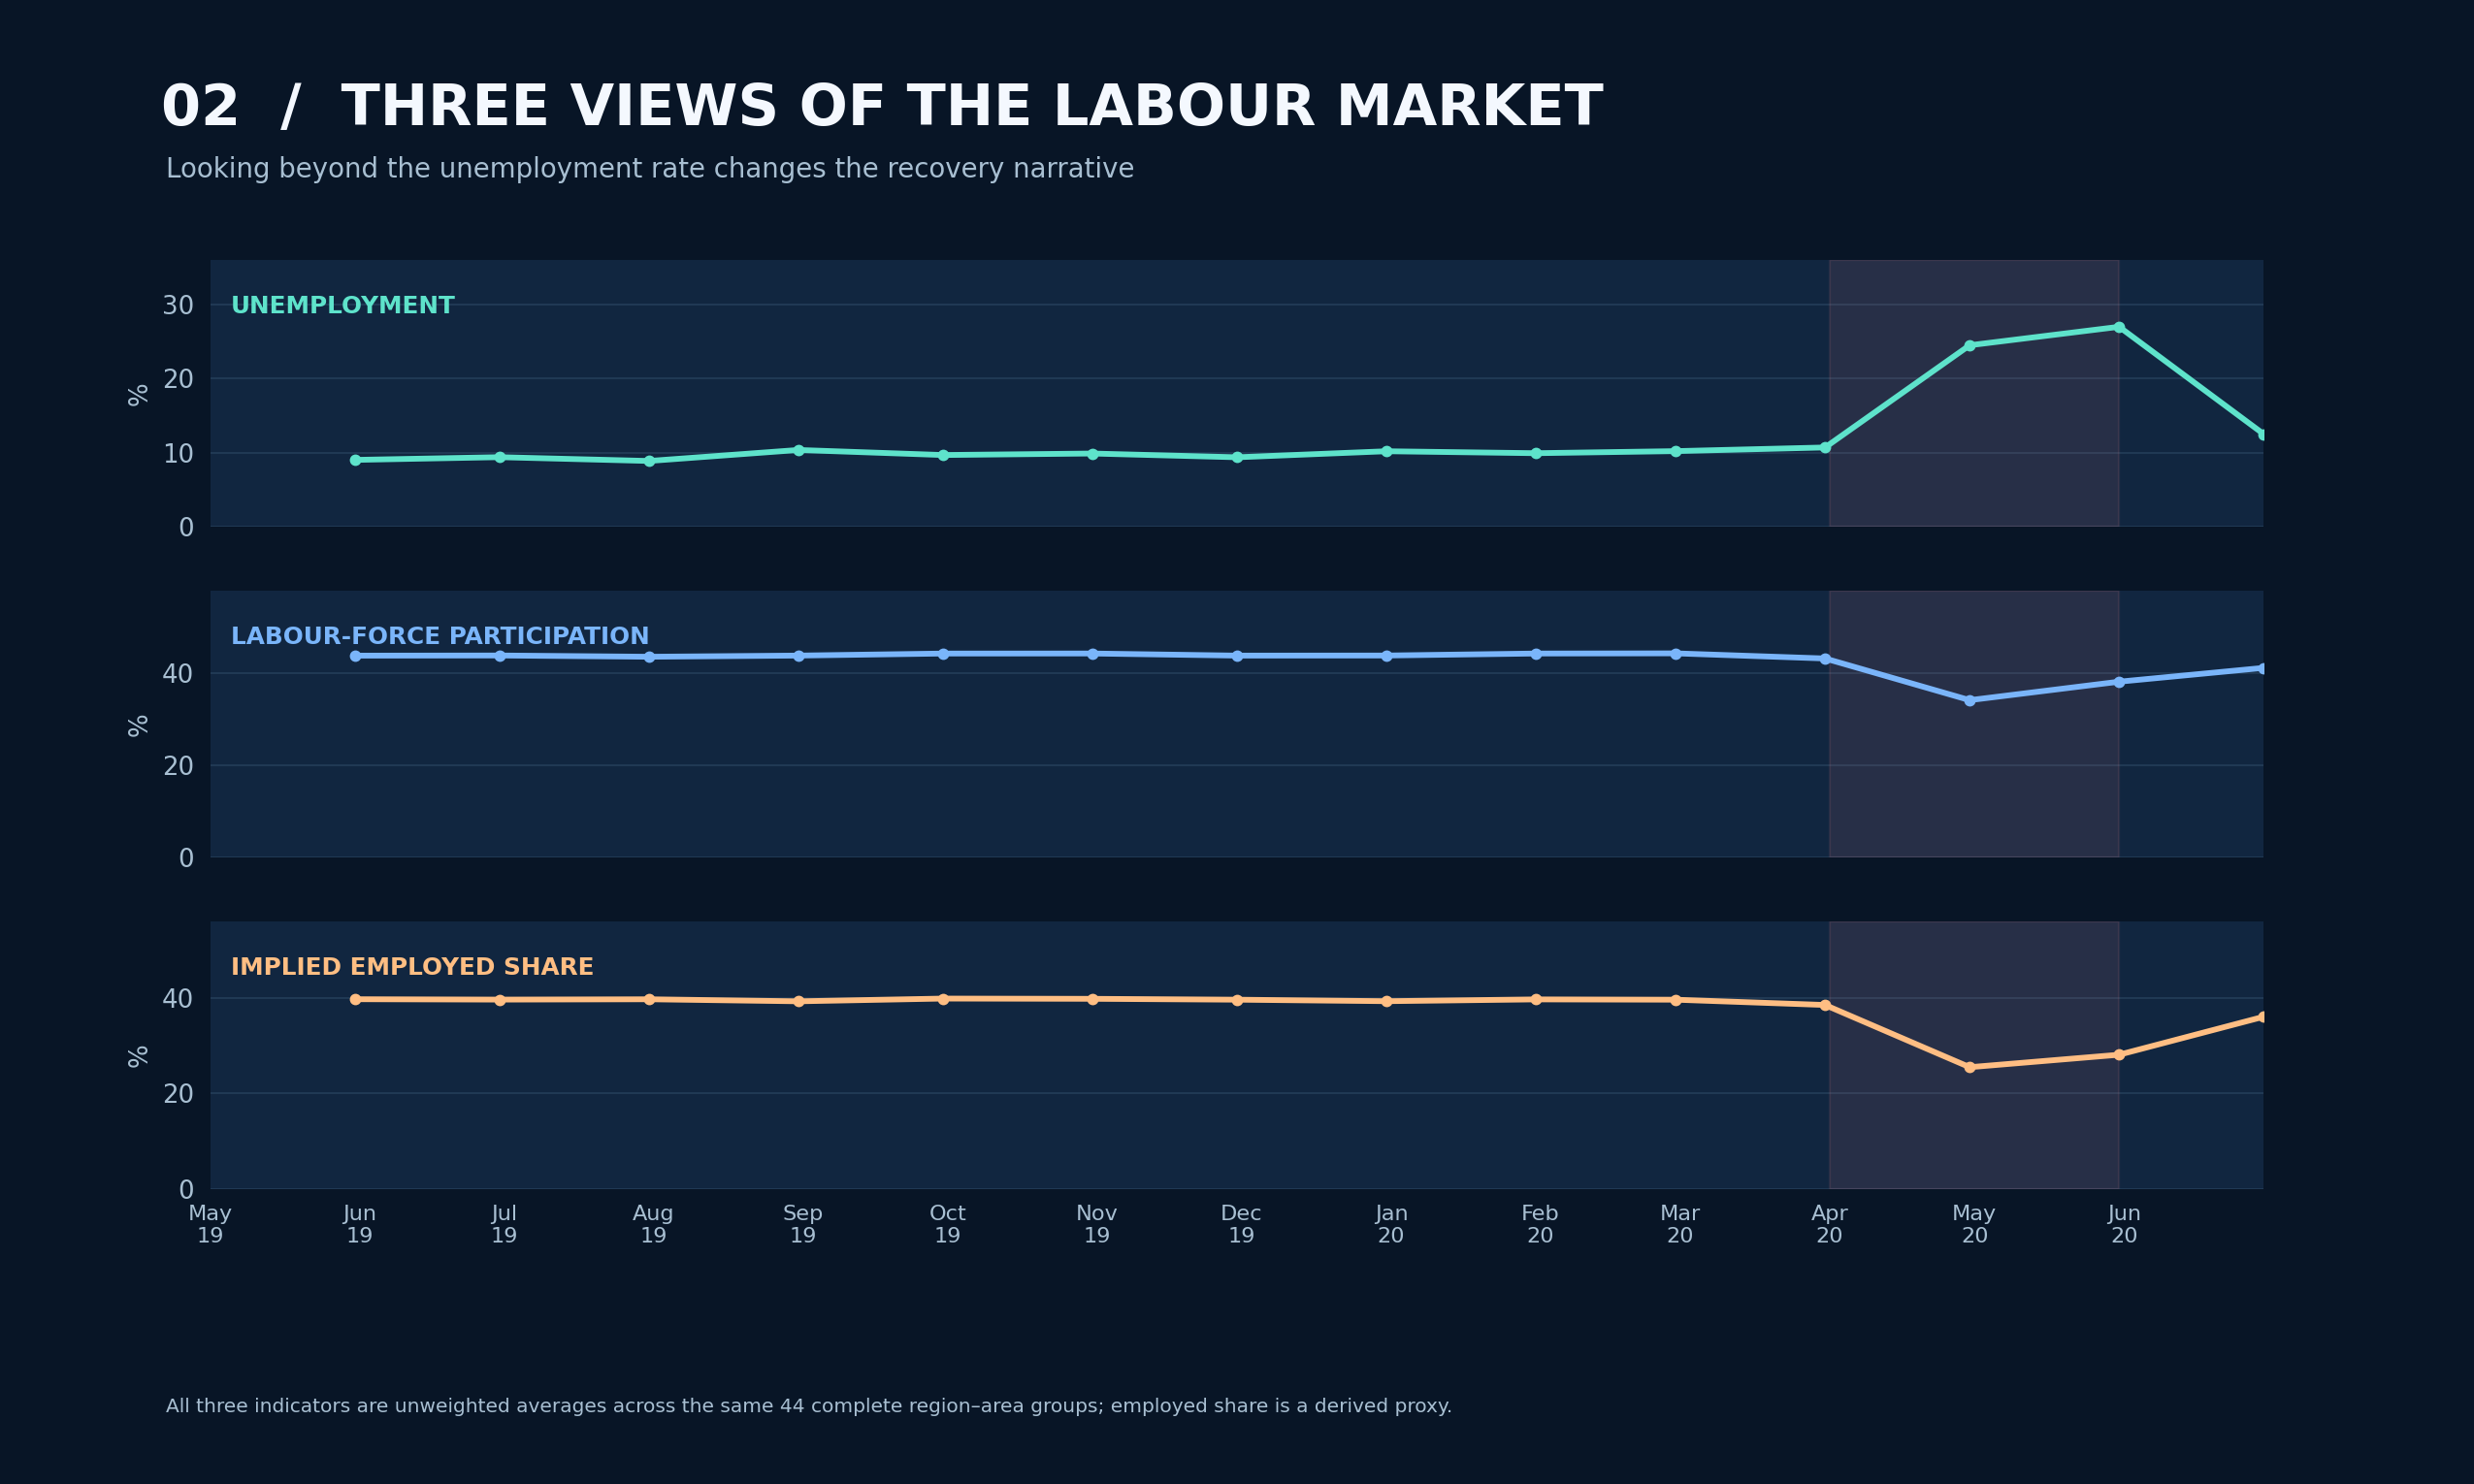

**Shock contrast.** Relative to baseline, April–May participation averaged **-7.83 pp**, and the implied employed share averaged **-12.85 pp** across the complete geographic groups.

**June contrast.** Although unemployment declined to **12.50%**, the June participation mean remained **-2.83 pp** and the implied employed-share mean **-3.58 pp** relative to their pre-shock baselines.

In [12]:
display(Image(filename=str(OUT/'02_three_indicators.png'),width=1150))
display(Markdown(f"""**Shock contrast.** Relative to baseline, April–May participation averaged **{s['lfpr_shock_pp']:+.2f} pp**, and the implied employed share averaged **{s['epr_shock_pp']:+.2f} pp** across the complete geographic groups.

**June contrast.** Although unemployment declined to **{s['june_ur']:.2f}%**, the June participation mean remained **{s['lfpr_june_residual_pp']:+.2f} pp** and the implied employed-share mean **{s['epr_june_residual_pp']:+.2f} pp** relative to their pre-shock baselines."""))

---
# Chapter 8 · Testing the apparent June recovery

**Question.** How many individual geographic groups had returned to their earlier conditions by June?

**Approach.** Compare June against each unit's *own* pre-shock baseline, not against a uniform national target. A group can record unemployment below baseline but still have an implied employment share below baseline if participation has changed.

The June reading is only **one month**. A short-term reversal is not evidence that long-term employment patterns, earnings or individual job outcomes fully recovered.

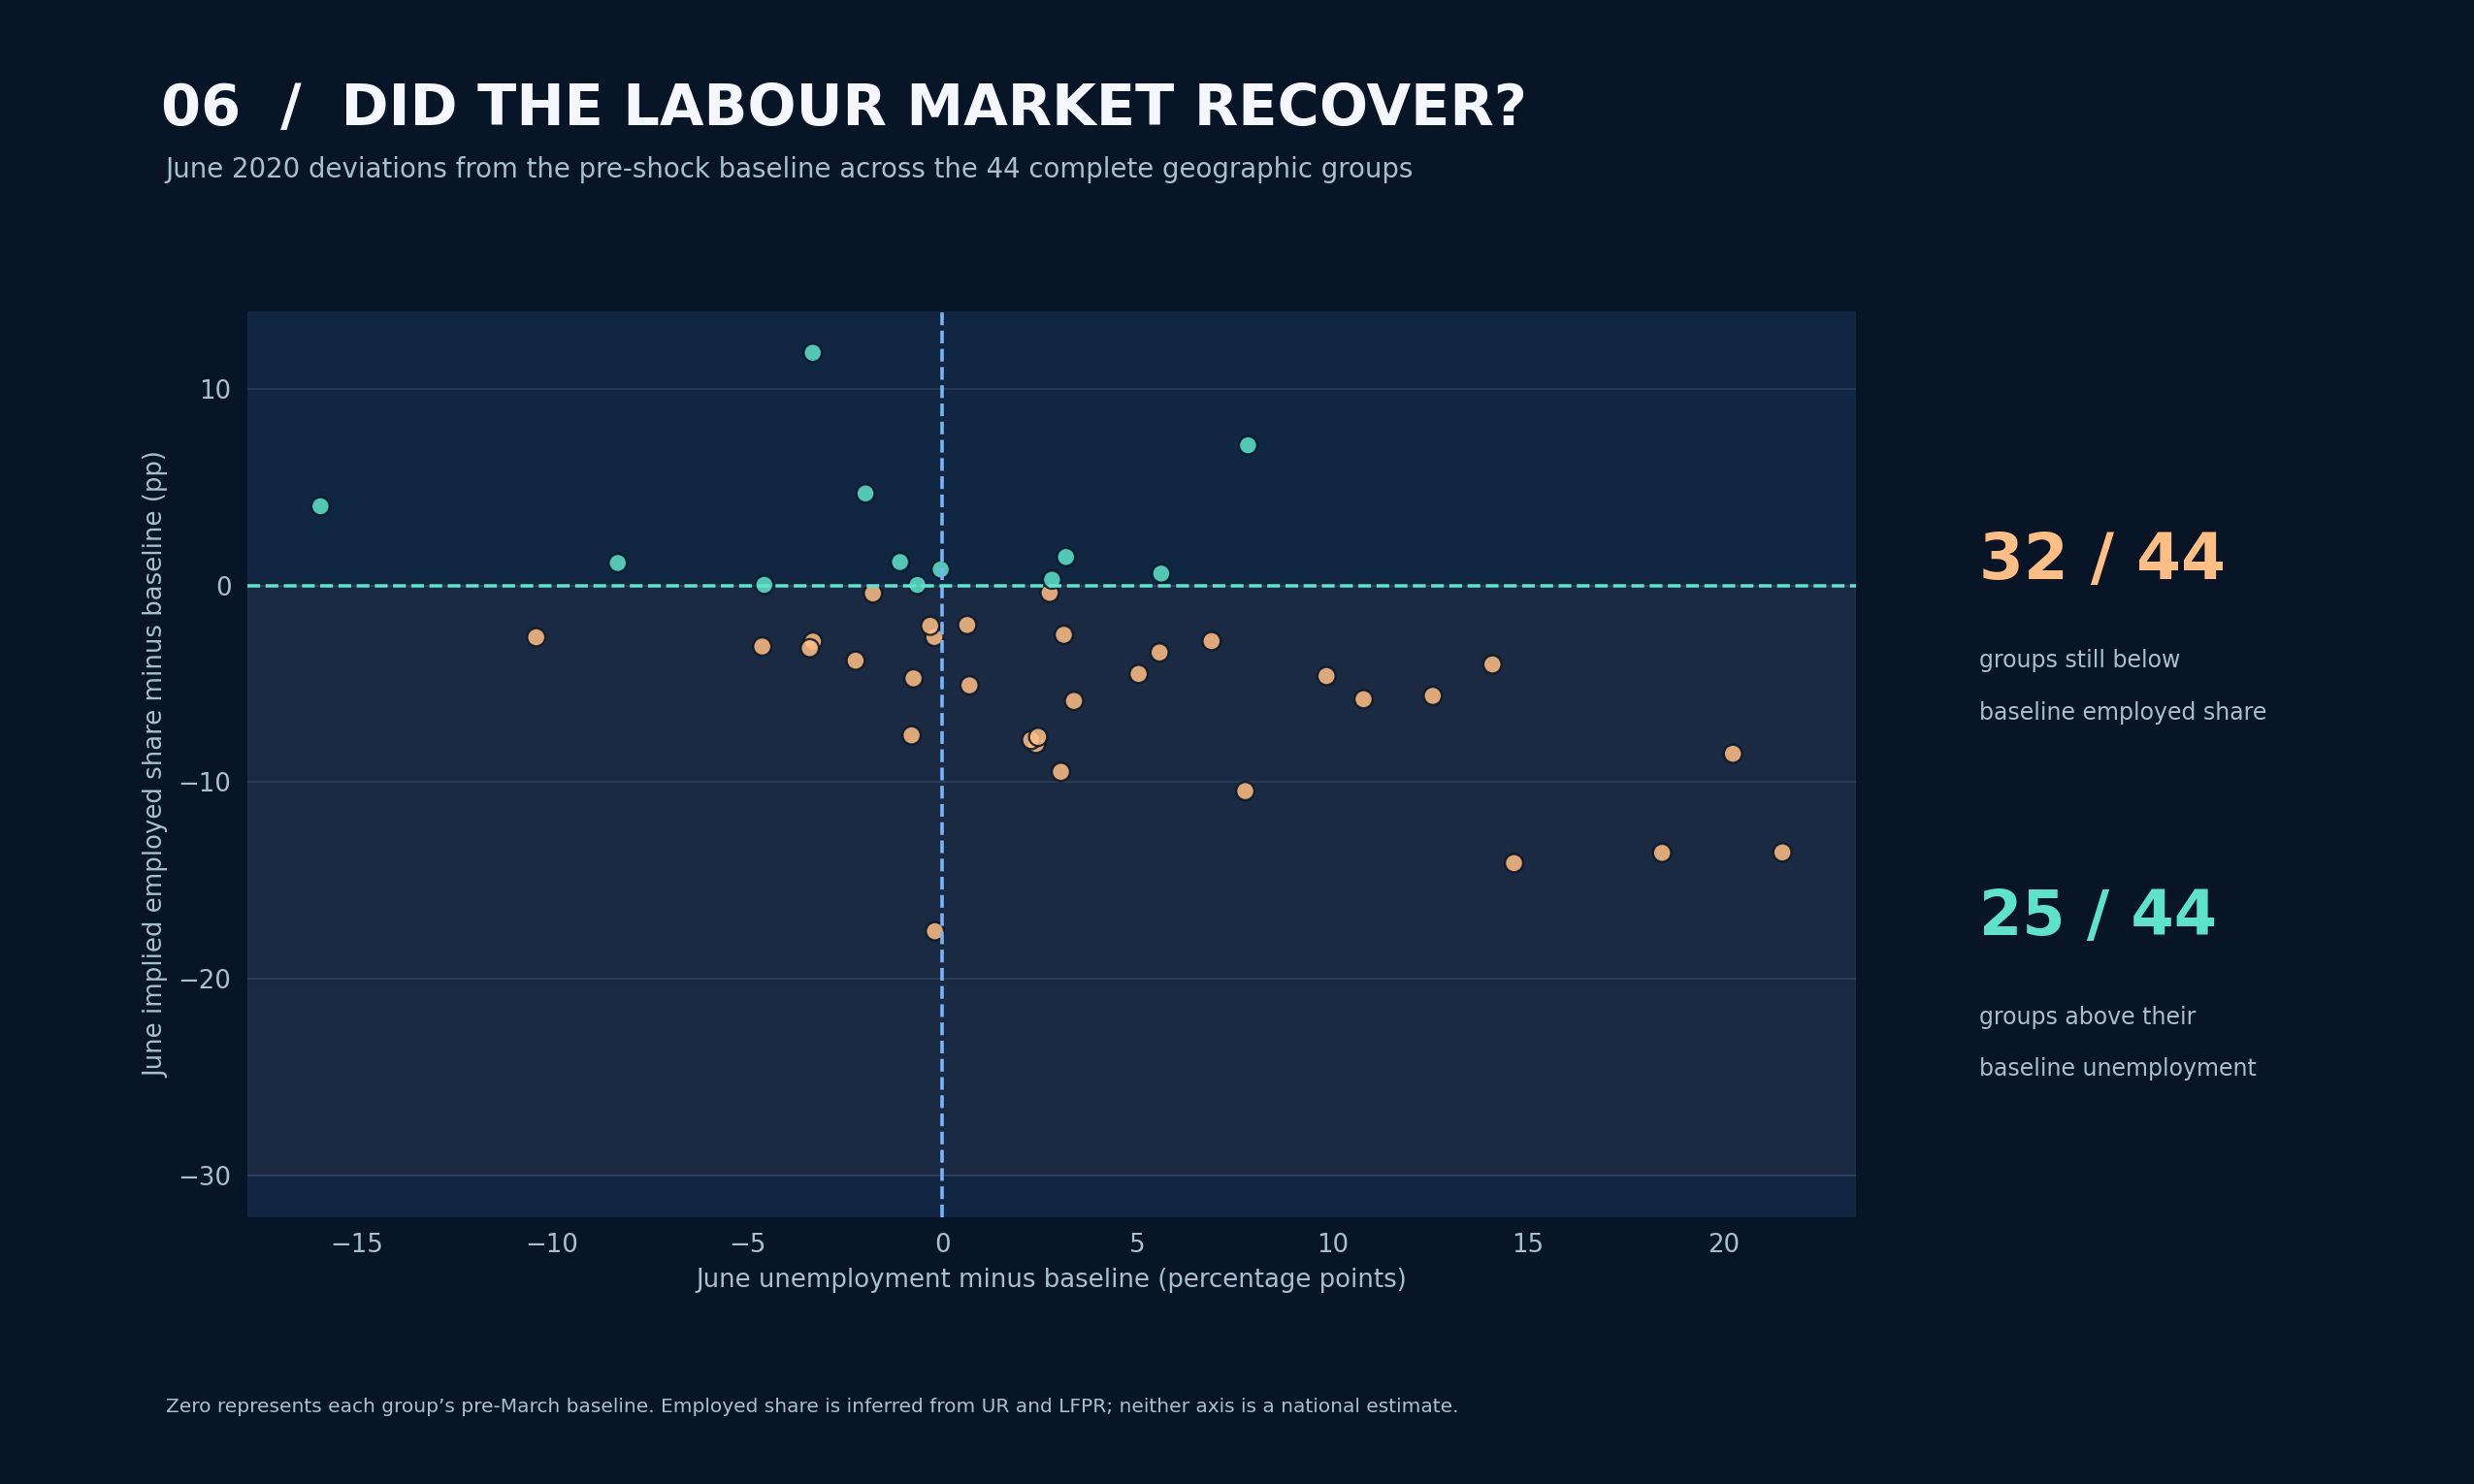

In June, **32 of 44 complete geographic groups** had an implied employed share **below** their earlier baseline. **34 of 44** also had participation below baseline, while **25 of 44** still had unemployment above baseline.

The consistent-panel averages show the distinction directly: employed share was **39.62%** during baseline, **26.78%** in April–May and **36.05%** in June. These are unweighted **group averages**, not a national population ratio.

In [13]:
display(Image(filename=str(OUT/'06_june_recovery.png'),width=1120))
display(Markdown(f"""In June, **{s['units_epr_below_base_june']} of {s['complete_units']} complete geographic groups** had an implied employed share **below** their earlier baseline. **{s['units_lfpr_below_base_june']} of {s['complete_units']}** also had participation below baseline, while **{s['units_ur_above_base_june']} of {s['complete_units']}** still had unemployment above baseline.

The consistent-panel averages show the distinction directly: employed share was **{s['baseline_epr']:.2f}%** during baseline, **{s['shock_epr']:.2f}%** in April–May and **{s['june_epr']:.2f}%** in June. These are unweighted **group averages**, not a national population ratio."""))

---
# Chapter 9 · Robustness: composition, extremes and regional dependence

**Question.** How sensitive are the findings to inclusion of incomplete geographic histories, unusually large changes and the fact that rural and urban records come from the same region?

Our checks are deliberately modest and interpretable:

1. **All observed versus balanced groups**: a composition sensitivity comparison, not a correction to make either estimate nationally representative.
2. **Median and interquartile spread**: describe typical geographic-unit changes without reliance on extreme cells.
3. **Region-resampling interval**: resample regions (with their rural/urban groups together) to see how the *descriptive complete-panel mean change* responds to the included regions. This is **not** an official survey confidence interval, and no causal or population inference is claimed.

We do **not** reuse the original notebook's rural–urban t-test or regional ANOVA of employed counts as primary evidence. Their comparison targets and independence assumptions do not suit our research question.

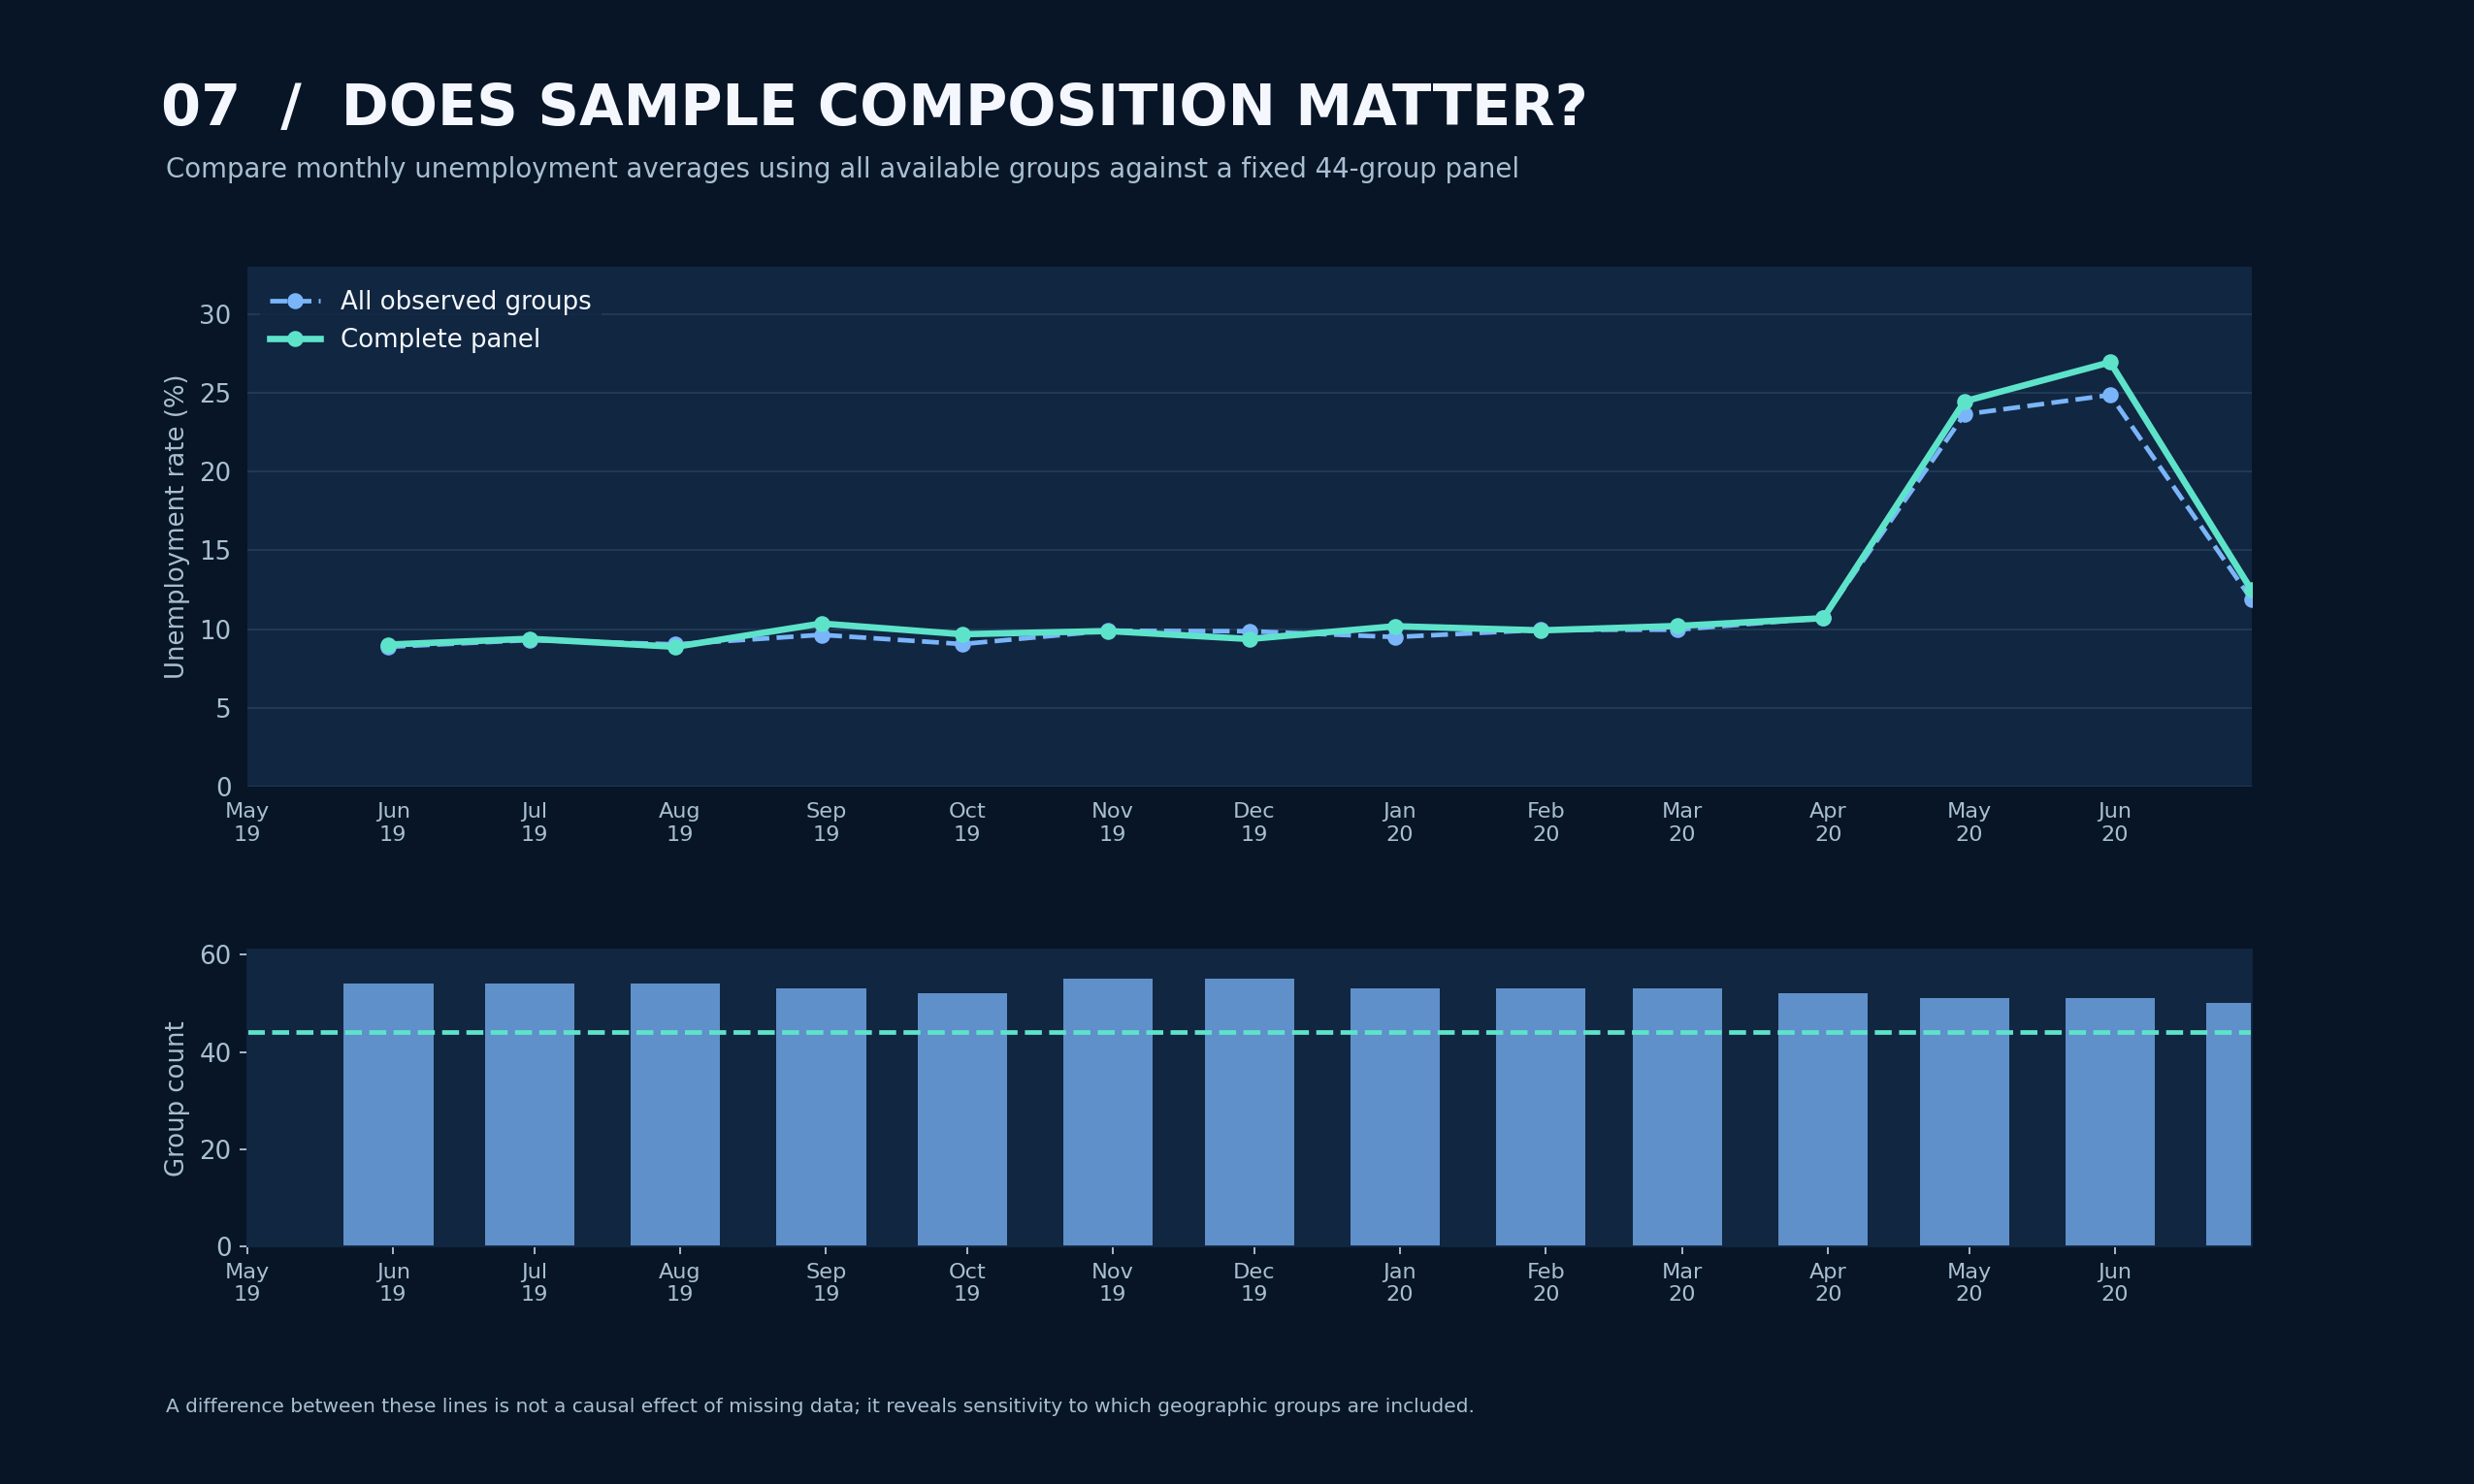

**Sensitivity results.** May 2020's all-available-row unemployment average was **24.88%**, versus **26.96%** in the complete panel (a **+2.08 pp** difference). The complete-panel April–May shock change had a **median of +13.31 pp** (interquartile range **8.31–18.99 pp**). A deterministic region-resampling exercise gave a **11.33 to 21.66 pp** sensitivity interval for its descriptive mean; it is *not* a population confidence interval.

In [14]:
display(Image(filename=str(OUT/'07_composition_sensitivity.png'),width=1100))
display(Markdown(f"""**Sensitivity results.** May 2020's all-available-row unemployment average was **{s['may_all_ur']:.2f}%**, versus **{s['may_balanced_ur']:.2f}%** in the complete panel (a **{s['may_balanced_ur']-s['may_all_ur']:+.2f} pp** difference). The complete-panel April–May shock change had a **median of {s['shock_ur_median_delta_pp']:+.2f} pp** (interquartile range **{s['shock_ur_q1_pp']:.2f}–{s['shock_ur_q3_pp']:.2f} pp**). A deterministic region-resampling exercise gave a **{s['shock_ur_region_resample_low_pp']:.2f} to {s['shock_ur_region_resample_high_pp']:.2f} pp** sensitivity interval for its descriptive mean; it is *not* a population confidence interval."""))

---
# Chapter 10 · Project conclusion

**Question answered.** The data supports a widespread short-term worsening of unemployment in April–May 2020, substantial geographic variation, and a June decline in unemployment rates. In the consistently observed geographic groups, participation and the implied employed share had not, on average, returned to their earlier baseline by June.

### What this analysis adds beyond a generic exploratory notebook

- Treats geographic group and monthly panel coverage as part of the evidence.
- Compares changes within groups instead of confusing absolute employed **counts** with **rates**.
- Interprets unemployment jointly with participation and a transparently derived employed-share proxy.
- Compares a constant group panel against the all-available dataset average.
- Separates descriptive evidence, exploratory robustness and true survey-population inference.
- Grounds every chart in reproducible code and source observations.

### What we cannot conclude

- That these are India's official national unemployment rates.
- That specific lockdown restrictions **caused** measured changes (there is no identified counterfactual).
- Why any individuals left or entered the labour force.
- That June's improvement continued after June 2020 or that earnings/jobs fully recovered.
- A statistically valid national confidence interval without original survey weights/design information.
- That geographic extremes reflect population-weighted rankings.

### Practical analytical takeaway

**Never conclude that labour-market conditions have recovered on the basis of a falling unemployment rate alone.** Ask whether participation also recovered, whether the implied employment share improved, whether the same geographic groups were observed, and whether the measurement definitions remain compatible.

---
# Appendix · Reproducibility and publication checks

The notebook uses one CSV, the `src/` functions and the listed Python dependencies. Running from this folder should regenerate the portfolio images and calculation exports. The original CSV is not modified. For published figures, interpret the README's limitations alongside the charts.

**Data status.** The dataset is a Kaggle-hosted snapshot credited to its listing. A Kaggle listing alone does not establish the original producer's methodology, sampling variance or redistribution licence. Do not imply otherwise.

**Analytical status.** This is a descriptive historical case study, with uncertainty and missing-panel limitations documented in `reports/METHODOLOGY.md`.

Reproduced eight visuals, three analytical tables and metrics manifest.
Dataset SHA-256: caa83db2077f8e08ab87e0dd1298c25e698b9c3461b94dad21ab9faad5c72e1b


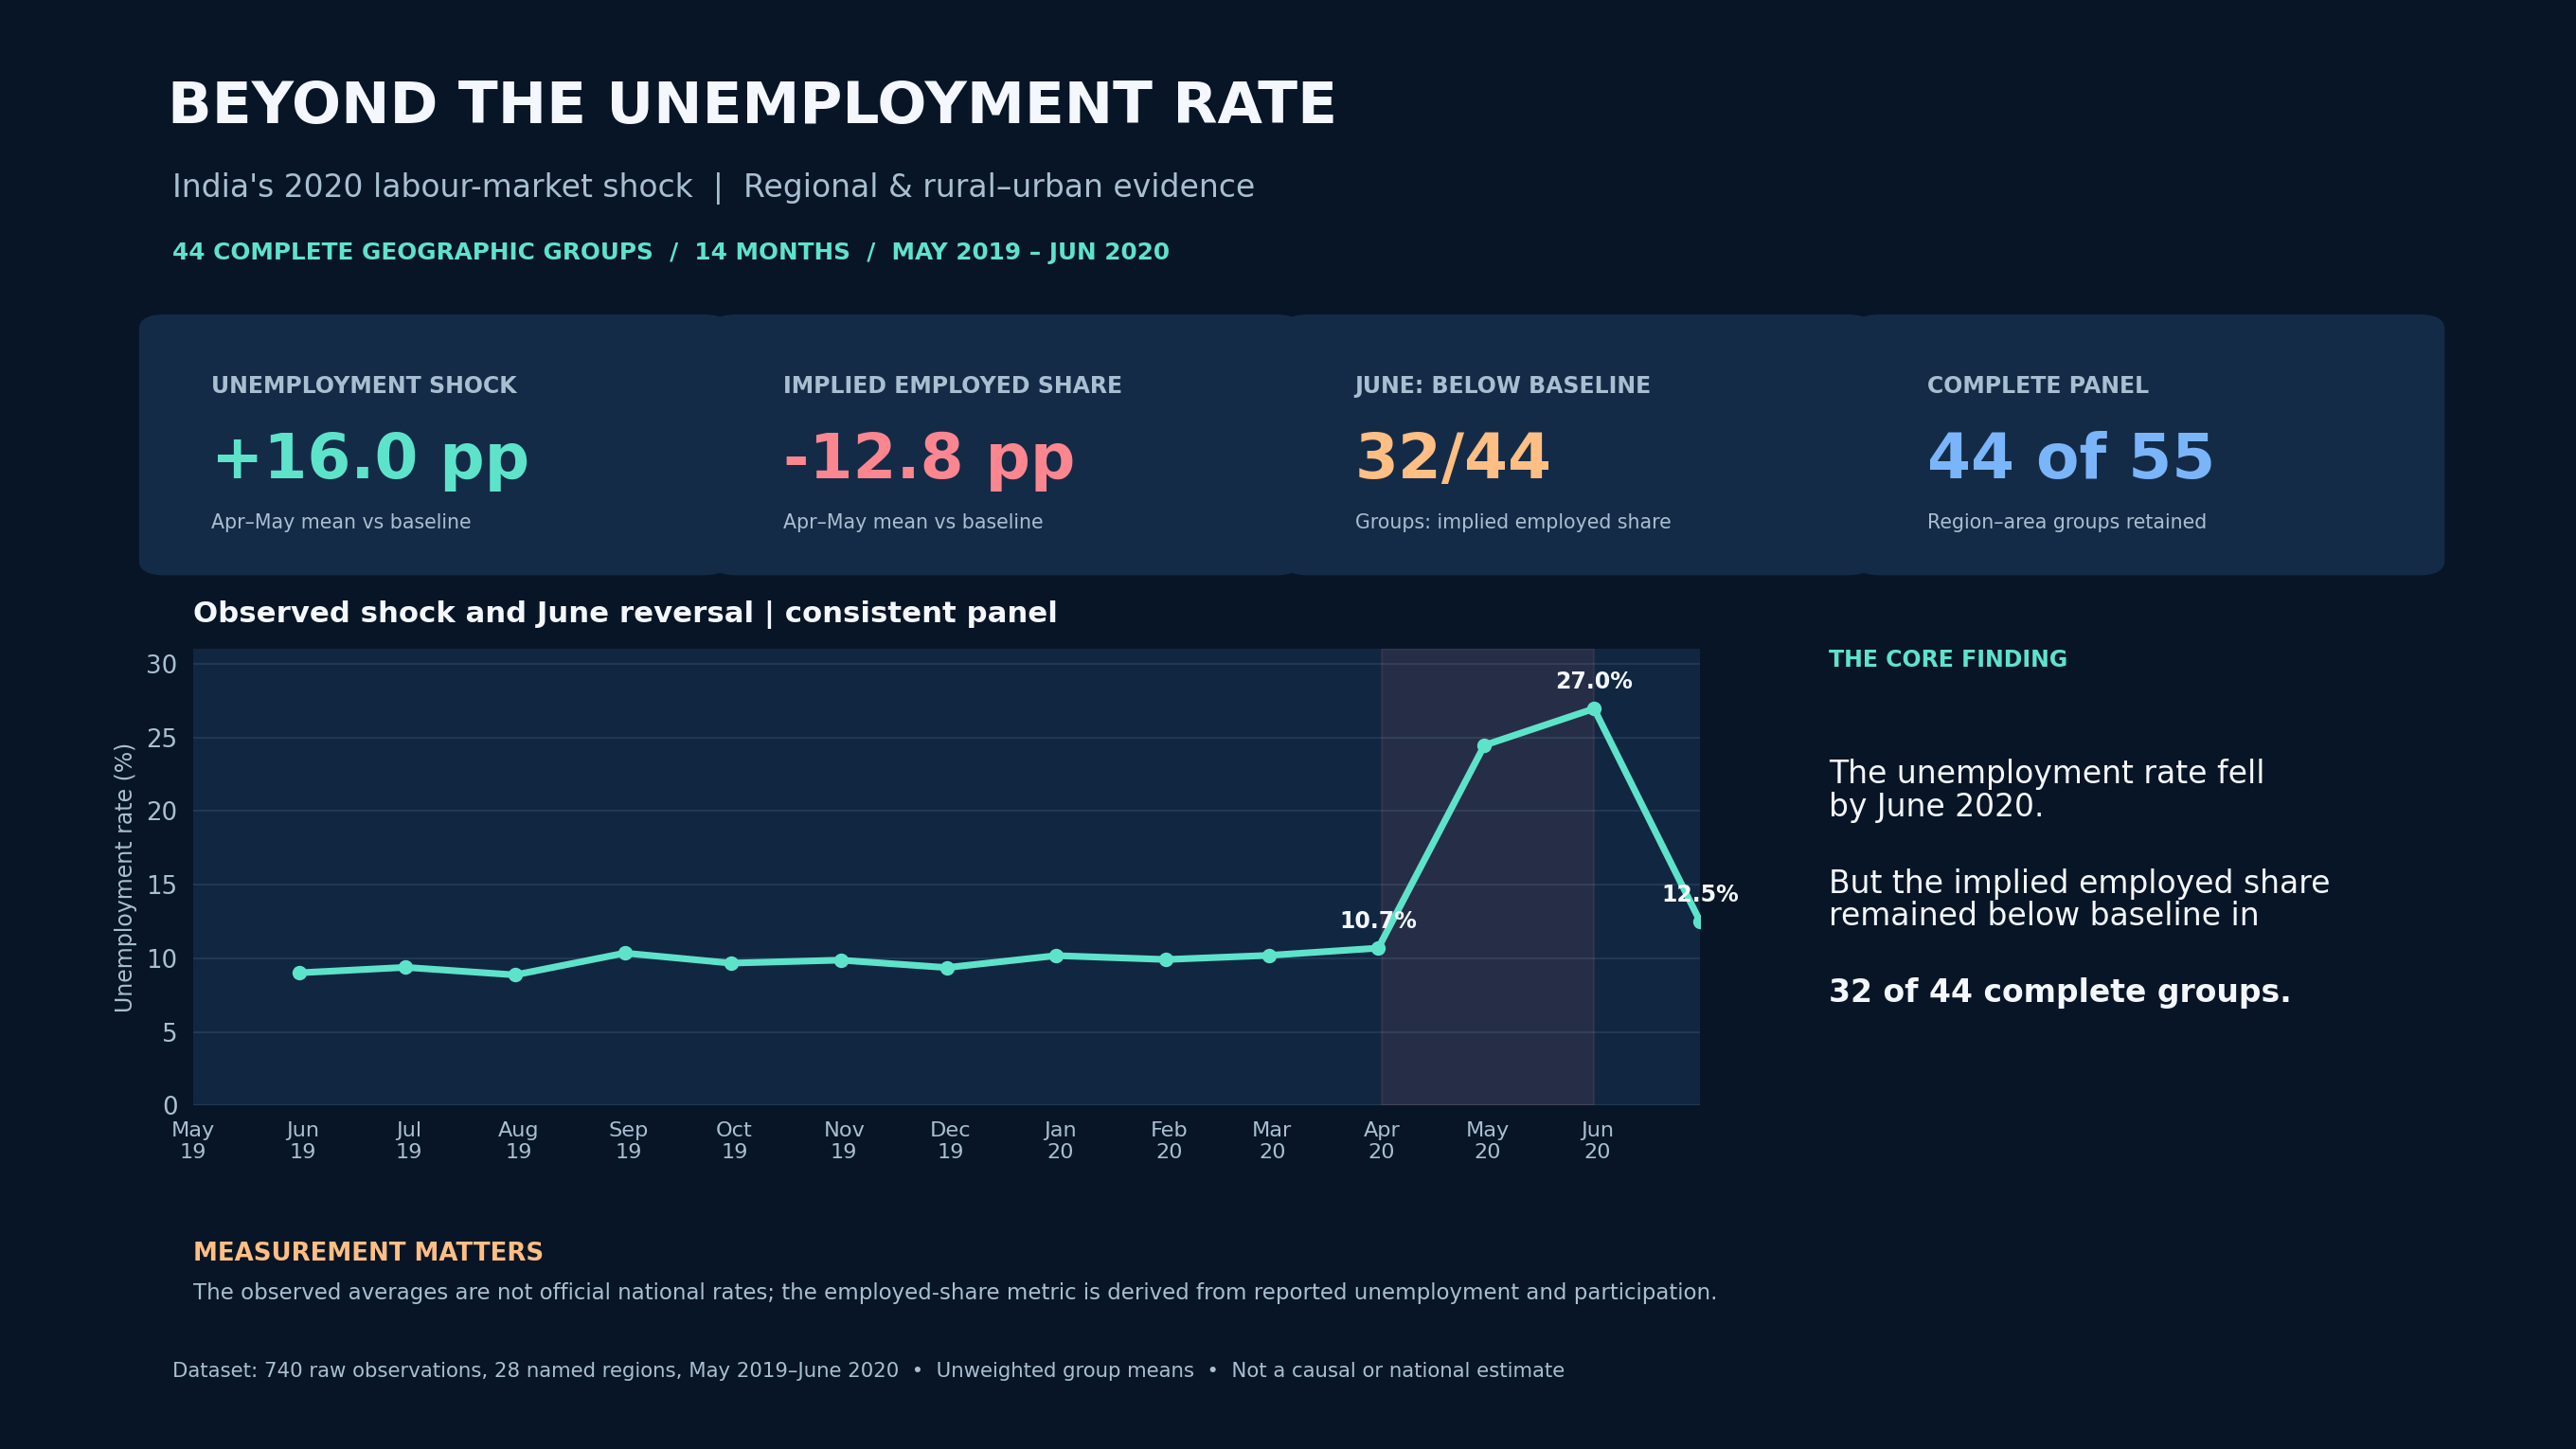

In [15]:
import json
summary = metrics(data,complete)
(REPORTS/'reproduced_metrics.json').write_text(json.dumps(summary,indent=2)+'\n',encoding='utf-8')
monthly(data).to_csv(REPORTS/'monthly_all_available.csv')
monthly(complete).to_csv(REPORTS/'monthly_balanced.csv')
comparison_table(complete).to_csv(REPORTS/'matched_group_comparisons.csv')
assert len(figures)==8 and all(f.is_file() for f in figures)
assert summary['raw_rows']==740 and summary['complete_units']==44 and summary['units_epr_below_base_june']==32
print('Reproduced eight visuals, three analytical tables and metrics manifest.')
print('Dataset SHA-256:',checksum(SOURCE))
display(Image(filename=str(OUT/'00_portfolio_cover.png'),width=1120))